# F-JEPA : détection précoce de pannes à partir de capteurs (données SYNTHÉTIQUES)

> ⚠️ **Toutes les valeurs de capteurs et tous les défauts de ce notebook sont inventés** (voir `input/files/README_SYNTHETIQUE.md`). Seule la timeline marche/arrêt/cadence/produit vient de la Tablette mouleuse réelle. Ce notebook valide une **démarche** (pipeline, métriques, baselines contre JEPA) sur une vérité terrain connue. Il ne démontre rien sur une machine réelle.

**Données** (`input/files`) :
- `synthetic_sensors.csv.gz` : une ligne par minute du 01/09/2025 au 01/09/2026 ; marche, vitesse, produit, **température, vibration, courant**. C'est la **seule entrée des modèles**.
- `synthetic_labels_GROUND_TRUTH.csv.gz` et `synthetic_fault_events.csv` : vérité terrain (défaut en cours, sévérité, événements bénins). Utilisée **uniquement** pour les statistiques descriptives et l'évaluation.

**Question.** Toutes les heures, le modèle répond à : *« une panne va-t-elle survenir dans les 7 prochains jours ? »*

**Plan**
1. Chargement
2. **Statistiques descriptives** : vue d'ensemble, distributions, saisonnalité, produits, corrélations, catalogue des défauts, signature des défauts, tests statistiques sain/dégradé
3. Tokens horaires (une heure de capteurs = un token)
4. Cible, découpage et protocole (2 plis chronologiques)
5. Baselines : seuil de température, EWMA de vibration, résidus physiques, régression logistique, gradient boosting
6. JEPA : pré-entraînement auto-supervisé sur 7 jours d'historique, puis sonde linéaire, score de surprise, distance à la normale, fine-tuning
7. Résultats : ROC-AUC, intervalles de confiance, détection par panne (taux, avance), fausses alertes bénignes
8. Visualisation de la période de test
9. Hypothèses pré-enregistrées confrontées aux résultats, et conclusions

## 0. Paramètres

In [1]:
import os, time, copy, json, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression, HuberRegressor
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings("ignore", message="enable_nested_tensor")
warnings.filterwarnings("ignore", message="obj.round has no effect")
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

DATA_DIR = Path(os.environ.get("FJEPA_SYNTH", "../input/files"))
RESULTS_DIR = Path("results_capteurs"); RESULTS_DIR.mkdir(exist_ok=True)

TOK_H = 2                # un token = 2 heures de capteurs
TOKEN = f"{TOK_H}h"
WINDOW = 7 * 24 // TOK_H  # 84 tokens = 7 jours d'historique
def nt(h): return max(1, h // TOK_H)   # durée en heures -> nombre de tokens
HORIZON_H = 168          # cible : panne dans les 7 jours qui suivent
SPLIT = pd.Timestamp("2026-03-01")   # pli A : train sept. -> fév., test mars -> août ; pli B : l'inverse
REGIME_MIN = 90          # « régime établi » : en marche depuis au moins 90 min (constante thermique 40 min)
ALERT_FPR = 0.05         # budget de fausses alertes : 5 % des heures saines en alerte
PERSIST = 2              # une alerte = 2 tokens consécutifs (4 h) au-dessus du seuil
DETECT_WINDOW_D = 14     # heures « saines » : aucune panne dans les 14 jours qui suivent
SENSORS = ["temperature_c", "vibration_mm_s", "current_a"]
NOMS = {"temperature_c": "Température (°C)", "vibration_mm_s": "Vibration (mm/s RMS)", "current_a": "Courant (A)"}
TYPE_COL = {"roulement": "C0", "courroie": "C1", "blocage": "C2", "electrique_brutal": "C3"}

## 1. Chargement

On lit les capteurs (entrée des modèles) et, à part, la vérité terrain. On vérifie que l'échantillonnage est bien régulier à la minute.

In [2]:
sens = pd.read_csv(DATA_DIR / "synthetic_sensors.csv.gz", parse_dates=["timestamp"]).set_index("timestamp")
gt = pd.read_csv(DATA_DIR / "synthetic_labels_GROUND_TRUTH.csv.gz", parse_dates=["timestamp"],
                 dtype={"fault_id": str, "fault_type": str}).set_index("timestamp")
faults = pd.read_csv(DATA_DIR / "synthetic_fault_events.csv", parse_dates=["onset", "failure_or_maintenance_time"])
faults = faults.rename(columns={"failure_or_maintenance_time": "fin"})
faults["panne"] = faults.kind.eq("panne")
cfg = json.load(open(DATA_DIR / "synthetic_config.json"))["CFG"]
sens["product"] = sens["product"].str.strip()

pas = sens.index.to_series().diff().value_counts()
print(f"{len(sens):,} minutes, du {sens.index.min():%d/%m/%Y %H:%M} au {sens.index.max():%d/%m/%Y %H:%M}")
print("écart entre deux lignes :", dict(pas.head(3)))
print(f"{sens['product'].nunique()} produits, machine en marche {sens.running.mean():.1%} du temps")
sens.head()

526,262 minutes, du 01/09/2025 00:00 au 01/09/2026 11:01
écart entre deux lignes : {Timedelta('0 days 00:01:00'): np.int64(526261)}
27 produits, machine en marche 45.1% du temps


,running,speed,product,temperature_c,vibration_mm_s,current_a
timestamp,,,,,,
2025-09-01 00:00:00,0,0.0,inconnu,17.78,0.026,0.0
2025-09-01 00:01:00,0,0.0,inconnu,17.79,0.067,0.0
2025-09-01 00:02:00,0,0.0,inconnu,17.88,0.022,0.0
2025-09-01 00:03:00,0,0.0,inconnu,17.97,0.036,0.0
2025-09-01 00:04:00,0,0.0,inconnu,17.98,0.075,0.0


## 2. Statistiques descriptives

### 2.1 Vue d'ensemble et valeurs manquantes

Les trous de données (capteur déconnecté) sont des `NaN`. On compte leur nombre, et surtout leur organisation en **plages contiguës** : un trou de 5 heures ne se traite pas comme 300 minutes isolées.

In [3]:
def plages(mask):
    # Plages contiguës où mask est vrai : (début, durée en minutes).
    m = mask.astype(int).values
    d = np.diff(np.r_[0, m, 0]); s, e = np.where(d == 1)[0], np.where(d == -1)[0]
    return pd.DataFrame({"debut": mask.index[s], "duree_min": e - s})

rows = []
for c in SENSORS:
    p = plages(sens[c].isna())
    rows.append({"capteur": c, "NaN": int(sens[c].isna().sum()), "% NaN": 100 * sens[c].isna().mean(),
                 "nb plages": len(p), "plus longue (h)": p.duree_min.max() / 60 if len(p) else 0,
                 "début plus longue": p.loc[p.duree_min.idxmax(), "debut"] if len(p) else None})
display(pd.DataFrame(rows).round(2))

# Le capteur figé (valeur constante) n'est pas un NaN : on le cherche par plages de valeurs identiques en marche.
same = sens.temperature_c.diff().eq(0) & sens.running.eq(1)
pf = plages(same); pf = pf[pf.duree_min >= 30]
print("Plages de température constante ≥ 30 min en marche (capteur figé ?) :")
display(pf.assign(duree_h=lambda d: d.duree_min / 60).round(1))

,capteur,NaN,% NaN,nb plages,plus longue (h),début plus longue
0,temperature_c,523,0.10,2,5.23,2026-04-04 22:06:00
1,vibration_mm_s,600,0.11,2,5.83,2026-07-16 10:17:00
2,current_a,258,0.05,1,4.30,2026-04-16 04:16:00


Plages de température constante ≥ 30 min en marche (capteur figé ?) :


,debut,duree_min,duree_h
3271,2026-05-20 08:36:00,100,1.7
3272,2026-05-20 10:18:00,38,0.6
3274,2026-05-20 11:02:00,65,1.1
3275,2026-05-20 12:12:00,47,0.8
3276,2026-05-20 13:06:00,165,2.8
3277,2026-05-20 15:53:00,61,1.0
3280,2026-05-20 17:22:00,140,2.3


### 2.2 Statistiques par état de la machine

À l'arrêt, le courant est nul, la vibration se réduit au bruit du capteur et la température redescend vers l'ambiante. Les statistiques n'ont de sens que **séparées par état**. On distingue aussi le **régime établi** (en marche depuis au moins 90 minutes), car la température met environ 40 minutes à se stabiliser après un démarrage.

In [4]:
run = sens.running.astype(bool)
seg = (run != run.shift()).cumsum()
depuis = sens.groupby(seg).cumcount()                       # minutes écoulées depuis le dernier changement d'état
regime = run & (depuis >= REGIME_MIN)
etat = np.where(~run, "arrêt", np.where(regime, "marche, régime établi", "marche, démarrage"))
sens["etat"] = etat

desc = sens.groupby("etat")[["speed"] + SENSORS].agg(["mean", "std", "min", "median", "max"]).T
desc.columns.name = None
display(desc.round(2))

print("Forme des distributions en régime établi (asymétrie, aplatissement) :")
rg = sens[regime]
display(pd.DataFrame({c: {"asymétrie": stats.skew(rg[c].dropna()), "kurtosis (excès)": stats.kurtosis(rg[c].dropna()),
                          "p1": rg[c].quantile(.01), "p99": rg[c].quantile(.99)} for c in SENSORS}).T.round(2))
print(f"Part du temps : {pd.Series(etat).value_counts(normalize=True).round(3).to_dict()}")

arrêt  marche, démarrage  marche, régime établi
speed          mean     0.00               0.90                   0.93
               std      0.00               0.17                   0.15
               min      0.00               0.19                   0.19
               median   0.00               0.97                   0.97
               max      0.00               1.26                   1.26
temperature_c  mean    20.17              44.80                  50.11
               std      9.06               7.90                   5.57
               min      9.50              10.38                  34.64
               median  18.02              45.39                  49.57
               max     77.51              81.46                  83.79
vibration_mm_s mean     0.06               1.63                   1.63
               std      0.03               0.85                   0.82
               min      0.02               0.61                   0.63
               median   0.05               1.29                   1.28
               max      0.28              10.42                  11.60
current_a      mean     0.00              12.12                  12.22
               std      0.00               1.59                   1.42
               min      0.00               4.88                   5.11
               median   0.00              12.38                  12.38
               max      0.00              20.27                  18.72

Forme des distributions en régime établi (asymétrie, aplatissement) :


,asymétrie,kurtosis (excès),p1,p99
temperature_c,1.02,2.94,40.25,66.87
vibration_mm_s,2.32,7.33,0.87,4.83
current_a,-0.95,2.67,7.37,15.28


Part du temps : {'arrêt': 0.549, 'marche, démarrage': 0.352, 'marche, régime établi': 0.099}


### 2.3 Distributions

En haut, les histogrammes en régime établi : la vérité terrain sépare les minutes **saines** de celles en **dégradation avancée** (sévérité > 0,5). En bas, la vitesse et les boîtes à moustaches mensuelles de la vibration.

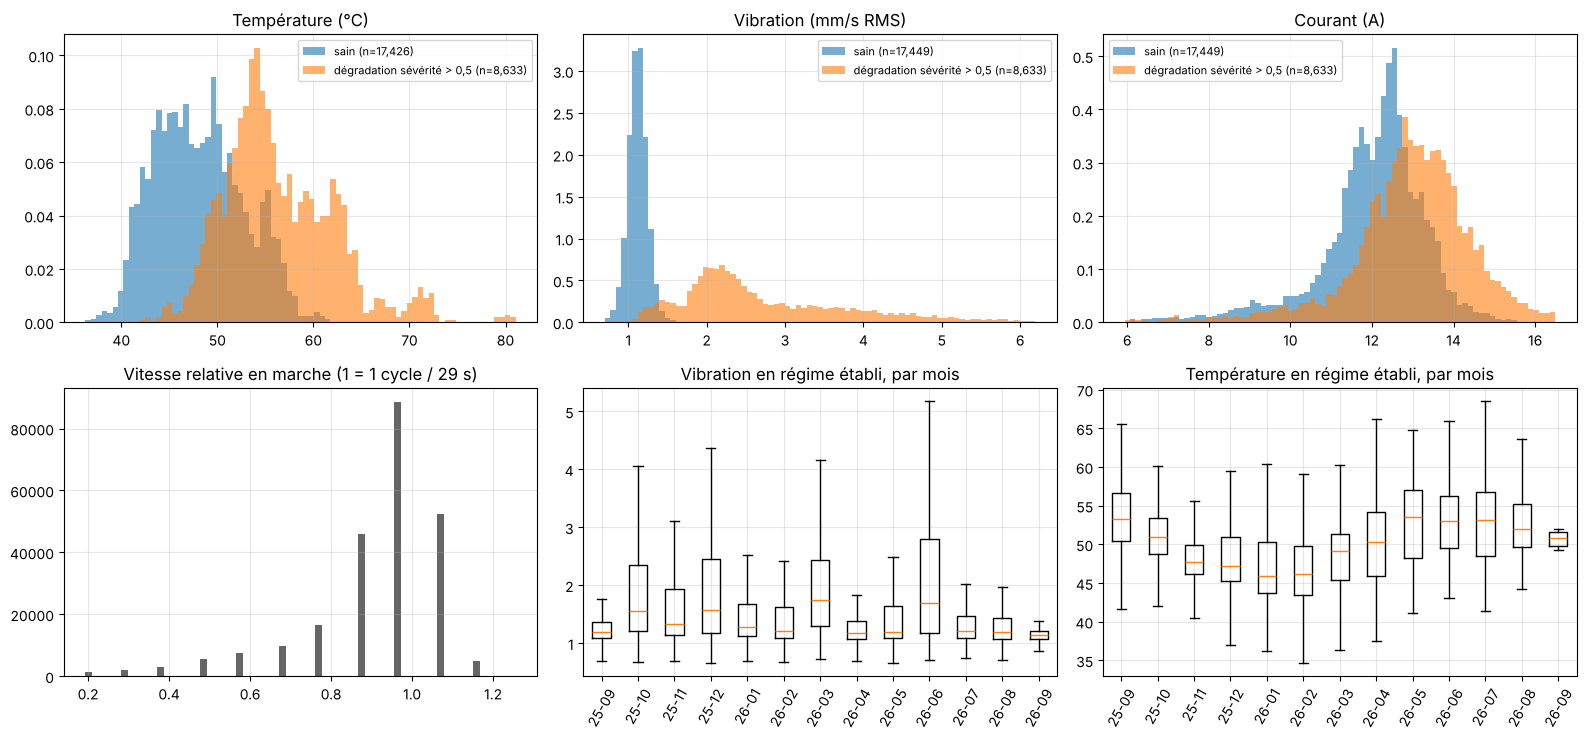

In [5]:
sev = gt.severity.reindex(sens.index).fillna(0)
sain = (gt.fault_type.isna() | gt.fault_type.eq("")) & (gt.preventive_degradation == 0)
fig, ax = plt.subplots(2, 3, figsize=(16, 7.5))
for a, c in zip(ax[0], SENSORS):
    v_s, v_d = sens.loc[regime & sain, c].dropna(), sens.loc[regime & (sev > .5), c].dropna()
    bins = np.linspace(v_s.quantile(.001), max(v_s.quantile(.999), v_d.quantile(.99)), 80)
    a.hist(v_s, bins, density=True, alpha=.6, label=f"sain (n={len(v_s):,})")
    a.hist(v_d, bins, density=True, alpha=.6, label=f"dégradation sévérité > 0,5 (n={len(v_d):,})")
    a.set_title(NOMS[c]); a.legend(fontsize=8)
ax[1, 0].hist(sens.speed[run], 60, color="0.4"); ax[1, 0].set_title("Vitesse relative en marche (1 = 1 cycle / 29 s)")
mois = sens[regime].index.to_period("M")
data = [g.dropna().values for _, g in sens[regime].groupby(mois).vibration_mm_s]
ax[1, 1].boxplot(data, showfliers=False, tick_labels=[str(m)[2:] for m in sorted(mois.unique())])
ax[1, 1].set_title("Vibration en régime établi, par mois"); ax[1, 1].tick_params(axis="x", rotation=60)
data = [g.dropna().values for _, g in sens[regime].groupby(mois).temperature_c]
ax[1, 2].boxplot(data, showfliers=False, tick_labels=[str(m)[2:] for m in sorted(mois.unique())])
ax[1, 2].set_title("Température en régime établi, par mois"); ax[1, 2].tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.savefig(RESULTS_DIR / "distributions.png", dpi=110); plt.show()

### 2.4 L'année entière

Médiane journalière de chaque capteur en régime établi, et taux de marche par jour. Les fenêtres de défaut sont en rouge (panne) ou en gris (dégradation corrigée par une maintenance préventive), les anomalies bénignes en orange.

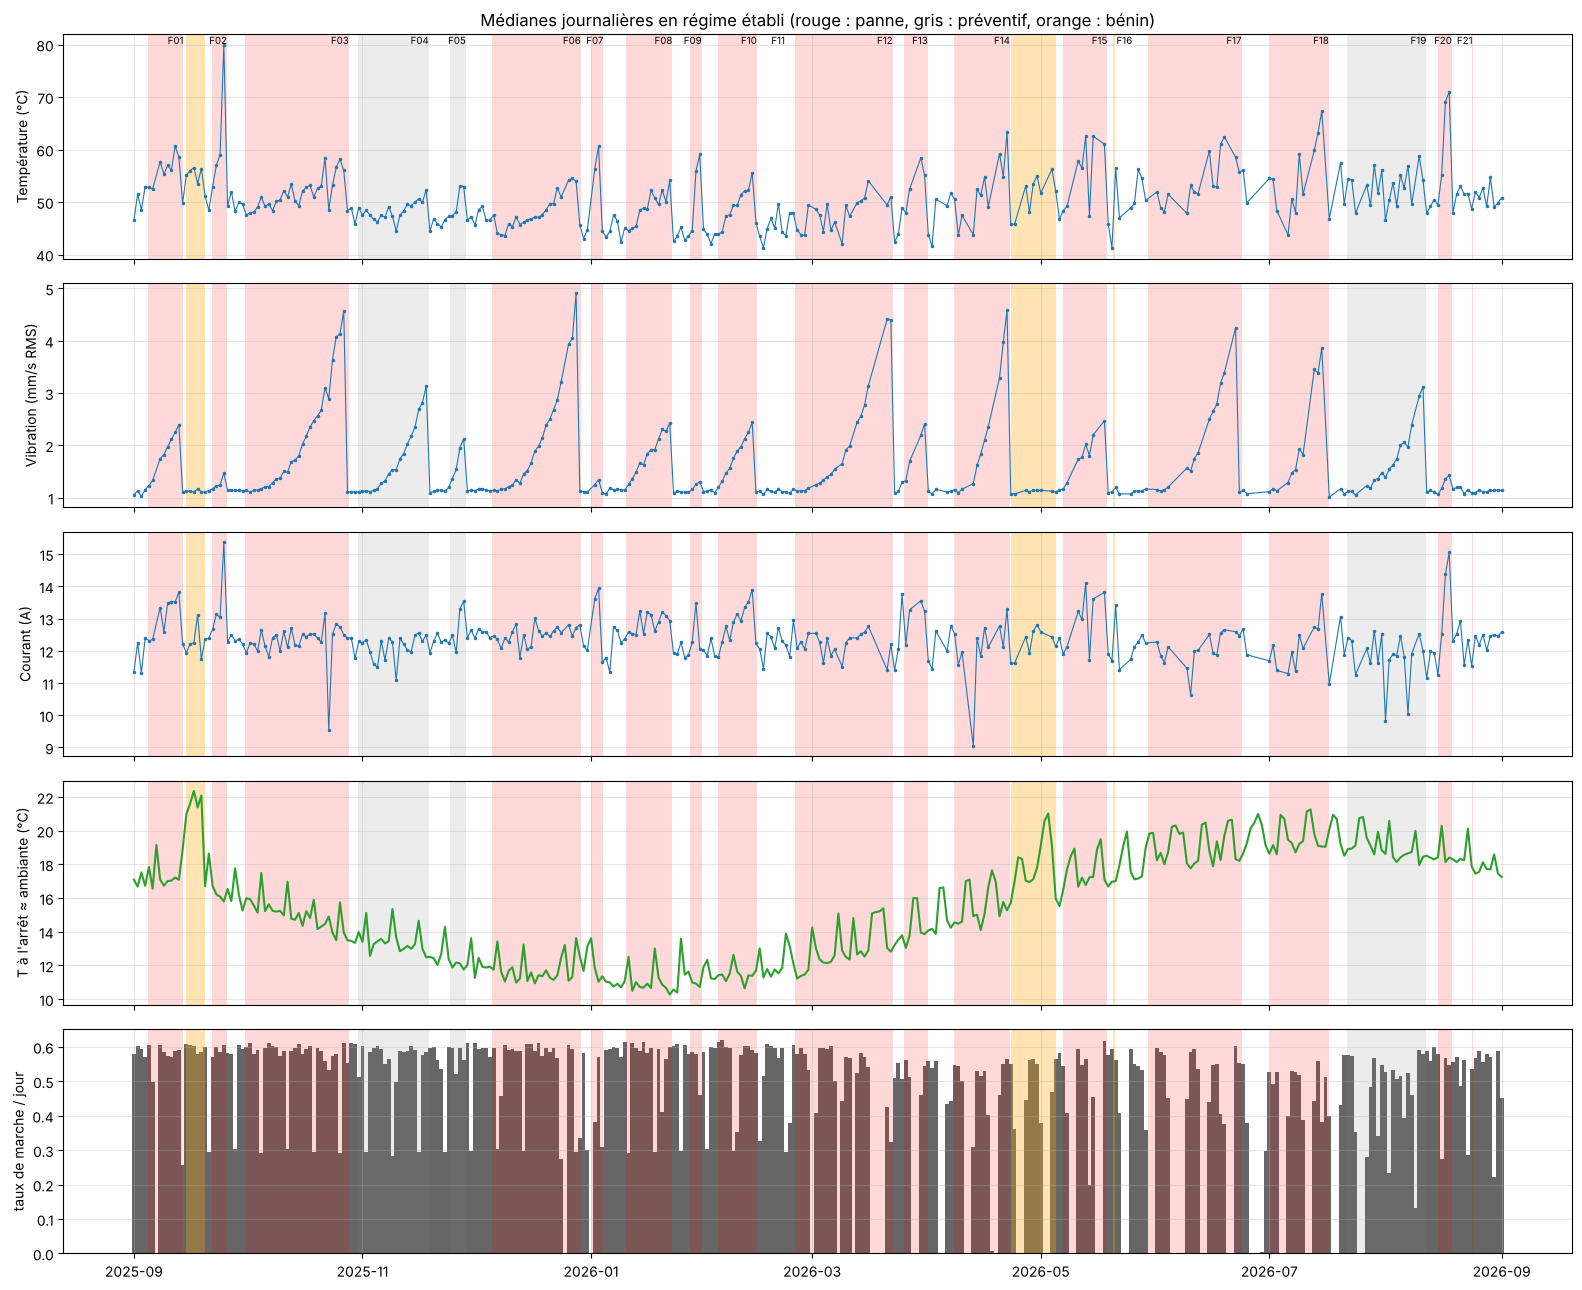

In [6]:
day = sens[regime].groupby(sens[regime].index.normalize())[SENSORS].median()
ambiant = sens[(~run) & (depuis >= 120)].temperature_c.resample("D").median()   # arrêt depuis 2 h : proche de l'ambiante
marche_j = sens.running.resample("D").mean()
benins = {"canicule": cfg["heatwave"][:2], "dérive capteur T": cfg["temp_drift"][:2],
          "capteur T figé": [cfg["stuck"][0], str(pd.Timestamp(cfg["stuck"][0]) + pd.Timedelta(hours=cfg["stuck"][1]))]}

def ombrer(a, labels=False):
    for f in faults.itertuples():
        a.axvspan(f.onset, f.fin, color="red" if f.panne else "0.5", alpha=.15, lw=0)
        if labels:
            a.text(f.fin, a.get_ylim()[1], f.fault_id, fontsize=7, ha="right", va="top")
    for nm, (d0, d1) in benins.items():
        a.axvspan(pd.Timestamp(d0), pd.Timestamp(d1), color="orange", alpha=.3, lw=0)

fig, ax = plt.subplots(5, 1, figsize=(16, 13), sharex=True)
for a, c in zip(ax, SENSORS):
    a.plot(day.index, day[c], ".-", ms=3, lw=.8); a.set_ylabel(NOMS[c]); ombrer(a, labels=(c == SENSORS[0]))
ax[3].plot(ambiant.index, ambiant, color="C2"); ax[3].set_ylabel("T à l'arrêt ≈ ambiante (°C)"); ombrer(ax[3])
ax[4].bar(marche_j.index, marche_j, width=1, color="0.4"); ax[4].set_ylabel("taux de marche / jour"); ombrer(ax[4])
ax[0].set_title("Médianes journalières en régime établi (rouge : panne, gris : préventif, orange : bénin)")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "annee.png", dpi=110); plt.show()

### 2.5 Profils hebdomadaires et journaliers

Taux de marche par jour de semaine et par heure, puis température ambiante estimée selon l'heure et le mois. Les modèles doivent apprendre à ne pas confondre ces cycles avec un défaut.

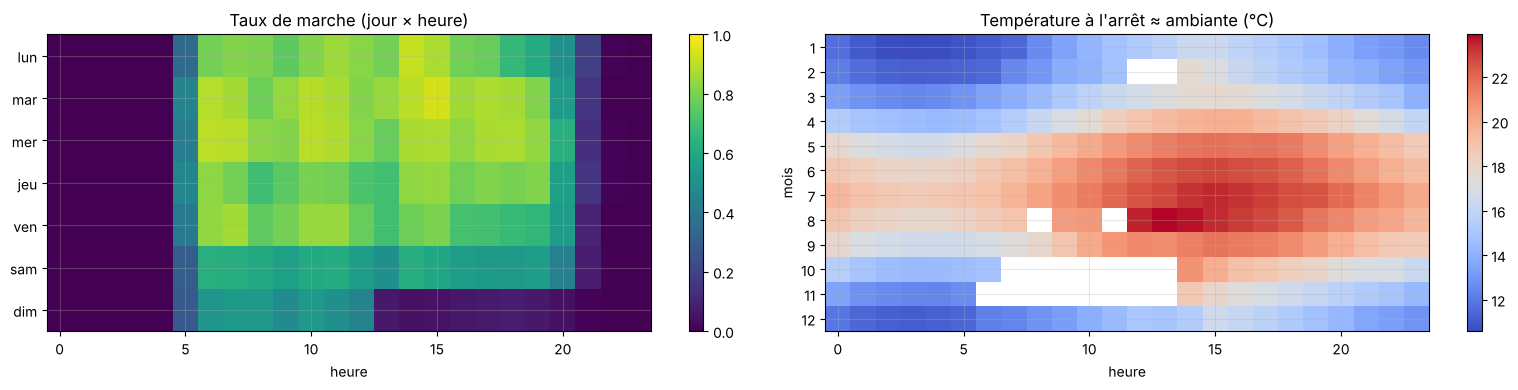

Taux de marche par jour de semaine : {'lun': 0.5, 'mar': 0.55, 'mer': 0.55, 'jeu': 0.51, 'ven': 0.49, 'sam': 0.37, 'dim': 0.18}


In [7]:
jours = ["lun", "mar", "mer", "jeu", "ven", "sam", "dim"]
prof = sens.running.groupby([sens.index.dayofweek, sens.index.hour]).mean().unstack()
amb = sens[(~run) & (depuis >= 120)].temperature_c
amb_prof = amb.groupby([amb.index.month, amb.index.hour]).median().unstack()
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
im = ax[0].imshow(prof, aspect="auto", cmap="viridis", vmin=0, vmax=1); ax[0].set_yticks(range(7), jours)
ax[0].set_xlabel("heure"); ax[0].set_title("Taux de marche (jour × heure)"); plt.colorbar(im, ax=ax[0])
im = ax[1].imshow(amb_prof, aspect="auto", cmap="coolwarm"); ax[1].set_yticks(range(len(amb_prof)), amb_prof.index)
ax[1].set_ylabel("mois"); ax[1].set_xlabel("heure"); ax[1].set_title("Température à l'arrêt ≈ ambiante (°C)"); plt.colorbar(im, ax=ax[1])
plt.tight_layout(); plt.show()
print("Taux de marche par jour de semaine :", sens.running.groupby(sens.index.dayofweek).mean().round(2).set_axis(jours).to_dict())

### 2.6 Produits

Chaque produit a son propre facteur de charge (inconnu des modèles), donc son propre niveau de courant et de vibration. Un modèle qui ignore le produit verra un changement de fabrication comme une anomalie.

In [8]:
pr = sens[regime & sain].groupby("product").agg(heures=("speed", lambda s: len(s) / 60), vitesse=("speed", "mean"),
                                                  courant=("current_a", "median"), vibration=("vibration_mm_s", "median"),
                                                  temperature=("temperature_c", "median"))
pr["courant / vitesse"] = pr.courant / pr.vitesse
pr = pr.sort_values("heures", ascending=False)
display(pr.head(12).round(2))
r = stats.spearmanr(pr["courant / vitesse"], pd.Series(json.load(open(DATA_DIR / "synthetic_config.json"))["product_load_factor"]).rename(lambda s: s.strip()).groupby(level=0).first().reindex(pr.index), nan_policy="omit")
print(f"{len(pr)} produits vus en régime sain. Corrélation de Spearman entre courant/vitesse mesuré et facteur de charge "
      f"caché du générateur : {r.statistic:.2f} (contrôle de cohérence, ce facteur n'est jamais donné aux modèles)")
chg = (sens["product"] != sens["product"].shift()).sum() - 1
print(f"{chg} changements de produit sur l'année, soit {chg / 365:.1f} par jour")

,heures,vitesse,courant,vibration,temperature,courant / vitesse
product,,,,,,
15 tartif moulage,107.73,0.91,12.21,1.12,46.56,13.42
145cm Brie 60% moulage,36.25,1.00,13.01,1.18,52.05,12.98
11 MT 200g moulage,30.98,0.94,11.33,1.05,44.07,12.05
Tarte 60% moulage,21.13,1.01,12.45,1.14,51.81,12.30
Carré 220g moulage,20.60,0.93,11.92,1.09,45.10,12.78
Tarte 50% stab moulage,16.98,1.00,13.40,1.20,55.37,13.37
11 tartif moulage,16.05,0.87,12.60,1.15,46.23,14.48
20 800 Brie 60% moulage,9.68,0.97,11.71,1.08,49.32,12.11
20 kg Brie 60% moulage,9.23,0.94,12.65,1.14,50.03,13.40


24 produits vus en régime sain. Corrélation de Spearman entre courant/vitesse mesuré et facteur de charge caché du générateur : 0.56 (contrôle de cohérence, ce facteur n'est jamais donné aux modèles)
4566 changements de produit sur l'année, soit 12.5 par jour


### 2.7 Corrélations

Corrélations de Spearman en régime établi et sain. Le courant suit la vitesse, et la température suit le courant avec retard : c'est le **contexte de charge** dont un détecteur doit tenir compte.

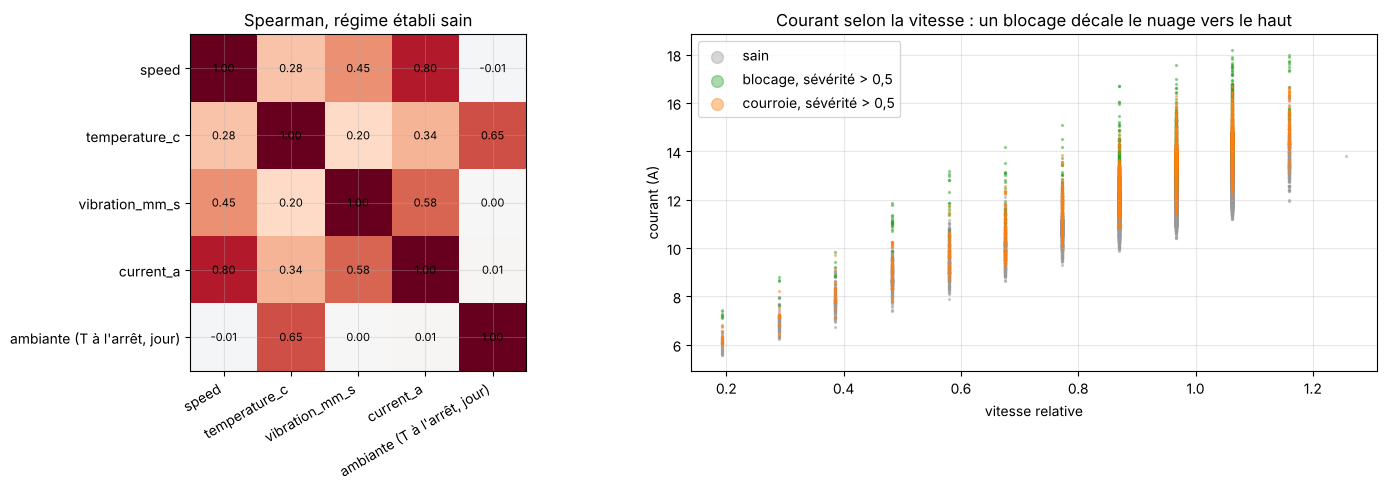

In [9]:
base = sens[regime & sain].copy()
base["ambiante (T à l'arrêt, jour)"] = ambiant.reindex(base.index.normalize()).values
cols = ["speed"] + SENSORS + ["ambiante (T à l'arrêt, jour)"]
cor = base[cols].corr("spearman")
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
im = ax[0].imshow(cor, cmap="RdBu_r", vmin=-1, vmax=1); ax[0].set_xticks(range(len(cols)), cols, rotation=30, ha="right")
ax[0].set_yticks(range(len(cols)), cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax[0].text(j, i, f"{cor.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax[0].set_title("Spearman, régime établi sain")
smp = sens[regime].sample(40_000, random_state=0)
for nom, m, col in [("sain", sain.reindex(smp.index), "0.6"), ("blocage, sévérité > 0,5", (gt.fault_type.reindex(smp.index).eq("blocage") & (sev.reindex(smp.index) > .5)), "C2"),
                    ("courroie, sévérité > 0,5", (gt.fault_type.reindex(smp.index).eq("courroie") & (sev.reindex(smp.index) > .5)), "C1")]:
    ax[1].scatter(smp.speed[m], smp.current_a[m], s=2, alpha=.4, color=col, label=nom)
ax[1].set_xlabel("vitesse relative"); ax[1].set_ylabel("courant (A)"); ax[1].legend(markerscale=6)
ax[1].set_title("Courant selon la vitesse : un blocage décale le nuage vers le haut")
plt.tight_layout(); plt.show()

### 2.8 Catalogue des défauts

21 défauts : 18 pannes et 3 dégradations corrigées par une maintenance préventive (cas censurés, qui ne sont pas des pannes).

,fault_id,type,kind,onset,fin,precursor_days
0,F01,courroie,panne,2025-09-04 18:48:00,2025-09-14 05:30:00,9.45
1,F02,blocage,panne,2025-09-21 23:16:00,2025-09-25 20:06:00,3.87
2,F03,roulement,panne,2025-09-30 16:32:00,2025-10-28 08:20:00,27.66
3,F04,roulement,degradation corrigée (préventif),2025-10-30 20:06:00,2025-11-18 16:30:00,18.85
4,F05,courroie,degradation corrigée (préventif),2025-11-24 11:20:00,2025-11-28 13:44:00,4.10
5,F06,roulement,panne,2025-12-05 11:36:00,2025-12-29 05:54:00,23.76
6,F07,blocage,panne,2026-01-01 02:36:00,2026-01-04 06:59:00,3.18
7,F08,courroie,panne,2026-01-10 05:05:00,2026-01-22 16:51:00,12.49
8,F09,blocage,panne,2026-01-27 08:25:00,2026-01-30 12:19:00,3.16
9,F10,courroie,panne,2026-02-03 21:52:00,2026-02-14 05:30:00,10.32


count    min  median    max
type              kind                                                         
blocage           panne                                 4   3.16    3.38   3.87
courroie          degradation corrigée (préventif)      1   4.10    4.10   4.10
                  panne                                 5   6.37   10.32  12.49
electrique_brutal panne                                 3   0.01    0.01   0.01
roulement         degradation corrigée (préventif)      2  18.85   20.02  21.20
                  panne                                 6  14.89   24.30  27.66

Temps entre deux pannes : médiane 18.4 j, min 5.5 j, max 61.9 j
Pannes par mois : {Period('2025-09', 'M'): 2, Period('2025-10', 'M'): 1, Period('2025-12', 'M'): 1, Period('2026-01', 'M'): 3, Period('2026-02', 'M'): 2, Period('2026-03', 'M'): 2, Period('2026-04', 'M'): 1, Period('2026-05', 'M'): 2, Period('2026-06', 'M'): 1, Period('2026-07', 'M'): 1, Period('2026-08', 'M'): 2}
Part du temps passée dans une fenêtre de précurseur de panne : 54.0% ; en dégradation préventive : 12.1%


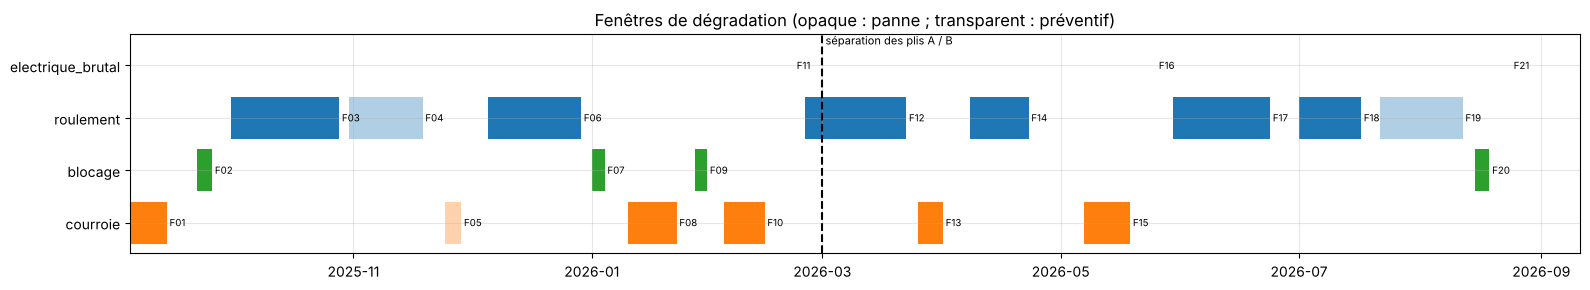

In [10]:
display(faults[["fault_id", "type", "kind", "onset", "fin", "precursor_days"]])
tab = faults.groupby(["type", "kind"]).precursor_days.agg(["count", "min", "median", "max"]).round(2)
display(tab)
pannes = faults[faults.panne].sort_values("fin")
ecart = pannes.fin.diff().dt.total_seconds() / 86400
print(f"Temps entre deux pannes : médiane {ecart.median():.1f} j, min {ecart.min():.1f} j, max {ecart.max():.1f} j")
print("Pannes par mois :", pannes.fin.dt.to_period("M").value_counts().sort_index().to_dict())
print(f"Part du temps passée dans une fenêtre de précurseur de panne : {gt.precursor_failure.mean():.1%} ; "
      f"en dégradation préventive : {gt.preventive_degradation.mean():.1%}")
fig, ax = plt.subplots(figsize=(16, 3))
for k, f in enumerate(faults.itertuples()):
    ax.barh(f.type, (f.fin - f.onset).total_seconds() / 86400, left=f.onset, color=TYPE_COL[f.type], alpha=1 if f.panne else .35)
    ax.text(f.fin, f.type, " " + f.fault_id, va="center", fontsize=7)
ax.axvline(SPLIT, color="k", ls="--"); ax.text(SPLIT, 3.4, " séparation des plis A / B", fontsize=8)
ax.set_title("Fenêtres de dégradation (opaque : panne ; transparent : préventif)"); plt.tight_layout(); plt.show()

### 2.9 Signature des défauts (analyse par époques superposées)

On aligne tous les défauts sur leur instant de panne (jour 0) et on trace, jour par jour, l'écart du capteur à sa référence saine. Pour le courant et la vibration, on divise par la médiane saine du même produit, ce qui retire l'effet du produit ; pour la température, on soustrait l'ambiante estimée. On voit ainsi à partir de quand chaque type de défaut devient visible, et sur quel capteur.

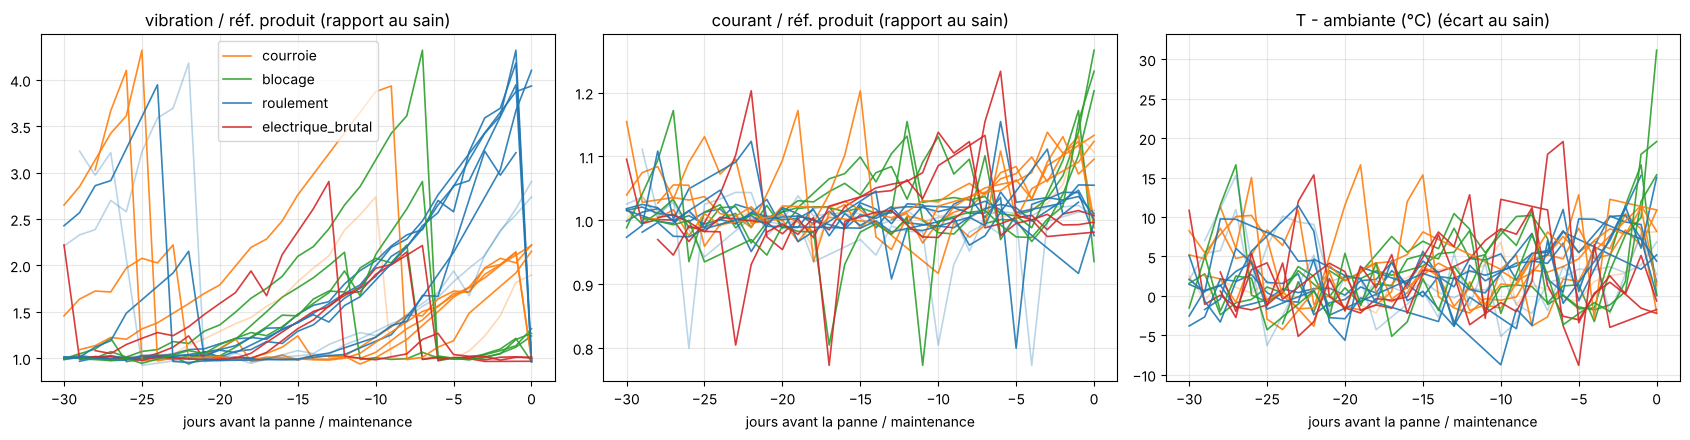

In [11]:
ref_prod = sens[regime & sain].groupby("product")[["current_a", "vibration_mm_s"]].median()
rg = sens[regime].copy()
rg["courant / réf. produit"] = rg.current_a / rg["product"].map(ref_prod.current_a)
rg["vibration / réf. produit"] = rg.vibration_mm_s / rg["product"].map(ref_prod.vibration_mm_s)
rg["T - ambiante (°C)"] = rg.temperature_c - ambiant.reindex(rg.index.normalize()).ffill().values
sig_cols = ["vibration / réf. produit", "courant / réf. produit", "T - ambiante (°C)"]
dj = rg.groupby(rg.index.normalize())[sig_cols].median()
ref_sain = dj[sain.groupby(sain.index.normalize()).mean().reindex(dj.index) > .99].median()
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for f in faults.itertuples():
    d = dj.loc[f.fin.normalize() - pd.Timedelta(days=30): f.fin.normalize()]
    x = (d.index - f.fin.normalize()).days
    for a, c in zip(ax, sig_cols):
        a.plot(x, d[c] / ref_sain[c] if c != "T - ambiante (°C)" else d[c] - ref_sain[c], "-", color=TYPE_COL[f.type],
               alpha=.9 if f.panne else .3, lw=1.2, label=f.type if f.fault_id in faults.groupby("type").fault_id.first().values else None)
for a, c in zip(ax, sig_cols):
    a.set_xlabel("jours avant la panne / maintenance"); a.set_title(c + (" (rapport au sain)" if "réf" in c else " (écart au sain)"))
ax[0].legend(); plt.tight_layout(); plt.savefig(RESULTS_DIR / "signatures.png", dpi=110); plt.show()

### 2.10 Tests statistiques : sain contre dégradé

Pour chaque capteur normalisé et chaque type de défaut, on compare les médianes horaires **saines** à celles de la **dernière semaine avant la panne** :
- **test de Mann-Whitney** : les deux distributions diffèrent-elles ?
- **delta de Cliff** : taille de l'effet, de -1 à 1 (|δ| > 0,47 est un « grand » effet).

On applique les mêmes tests aux **anomalies bénignes** : un écart significatif sur l'une d'elles montre qu'un seuil naïf déclencherait une fausse alerte.

Les heures successives sont autocorrélées, donc les p-valeurs sont trop optimistes : on regarde surtout la taille de l'effet.

In [12]:
rg["heure"] = rg.index.floor("h")
hh = rg.groupby("heure")[sig_cols].median()
g_h = gt.reindex(hh.index)
fin_h = pd.Series(np.nan, index=hh.index, dtype=object)
for f in faults.itertuples():
    fin_h[(hh.index >= f.fin - pd.Timedelta(days=7)) & (hh.index < f.fin)] = f.type + ("" if f.panne else " (préventif)")
sain_h = sain.resample("h").min().reindex(hh.index).fillna(False).astype(bool)

def cliff(a, b):
    a, b = np.asarray(a), np.asarray(b)
    return (np.sign(a[:, None] - b[None, :])).mean()

rows = []
groupes = {t: fin_h.eq(t) for t in ["roulement", "courroie", "blocage", "electrique_brutal"]}
for nm, (d0, d1) in benins.items():
    groupes["BÉNIN : " + nm] = pd.Series((hh.index >= pd.Timestamp(d0)) & (hh.index < pd.Timestamp(d1)), index=hh.index)
rng0 = np.random.default_rng(0)
for g, m in groupes.items():
    for c in sig_cols:
        a, b = hh.loc[m & ~sain_h | (m & g.startswith("BÉNIN")), c].dropna(), hh.loc[sain_h & ~m, c].dropna()
        if len(a) < 5: continue
        bs = rng0.choice(b.values, min(len(b), 3000), replace=False)
        rows.append({"groupe": g, "signal": c, "n heures": len(a), "médiane groupe": a.median(), "médiane saine": b.median(),
                     "p Mann-Whitney": stats.mannwhitneyu(a, b).pvalue, "delta de Cliff": cliff(a.values[:3000], bs)})
tests = pd.DataFrame(rows)
display(tests.pivot(index="groupe", columns="signal", values="delta de Cliff").round(2).style.background_gradient(cmap="RdBu_r", vmin=-1, vmax=1))
display(tests.round(4))

signal,T - ambiante (°C),courant / réf. produit,vibration / réf. produit
groupe,,,
BÉNIN : canicule,0.180000,-0.130000,-0.010000
BÉNIN : capteur T figé,-0.990000,-0.240000,-0.060000
BÉNIN : dérive capteur T,0.080000,-0.070000,-0.040000
blocage,0.620000,0.600000,0.630000
courroie,0.800000,0.660000,0.980000
electrique_brutal,0.870000,0.640000,0.780000
roulement,0.780000,0.420000,1.000000


,groupe,signal,n heures,médiane groupe,médiane saine,p Mann-Whitney,delta de Cliff
0,roulement,vibration / réf. produit,146,2.9615,0.9965,0.0000,1.0000
1,roulement,courant / réf. produit,146,1.0276,0.9992,0.0000,0.4249
2,roulement,T - ambiante (°C),146,40.5000,32.9075,0.0000,0.7794
3,courroie,vibration / réf. produit,171,1.7571,0.9964,0.0000,0.9819
4,courroie,courant / réf. produit,171,1.0747,0.9992,0.0000,0.6561
5,courroie,T - ambiante (°C),172,39.4250,32.9150,0.0000,0.7975
6,blocage,vibration / réf. produit,73,1.0895,0.9970,0.0000,0.6288
7,blocage,courant / réf. produit,73,1.0638,0.9993,0.0000,0.5999
8,blocage,T - ambiante (°C),73,40.3200,33.0775,0.0000,0.6182
9,electrique_brutal,vibration / réf. produit,13,1.2413,0.9954,0.0000,0.7752


### 2.11 Autocorrélation

L'autocorrélation des médianes horaires mesure la « mémoire » des signaux. Une forte autocorrélation à 24 h et à 168 h vient des cycles jour/semaine ; une autocorrélation qui reste élevée sur plusieurs jours traduit une dérive lente (dégradation, saison). C'est ce qui justifie une **fenêtre d'historique de 7 jours**.

In [13]:
hfull = hh.reindex(pd.date_range(hh.index.min(), hh.index.max(), freq="h"))
lags = [1, 6, 12, 24, 48, 72, 168, 336]
display(pd.DataFrame({c: [hfull[c].autocorr(l) for l in lags] for c in sig_cols}, index=[f"{l} h" for l in lags]).round(2))

,vibration / réf. produit,courant / réf. produit,T - ambiante (°C)
1 h,0.97,0.34,0.94
6 h,0.95,0.09,0.61
12 h,0.85,0.27,0.01
24 h,0.84,0.20,0.58
48 h,0.51,0.15,0.39
72 h,0.39,0.12,0.32
168 h,0.05,-0.00,0.26
336 h,-0.22,0.04,0.26


## 3. Tokens de 2 heures

Chaque tranche de 2 heures devient un **token** de 21 variables, calculées sans aucune information de vérité terrain :
- **activité** : part du temps en marche, en régime établi, vitesse moyenne, nombre de changements de produit ;
- **capteurs en marche** : moyenne, écart-type et 95e percentile de la vibration ; moyenne, écart-type et maximum du courant ; moyenne de la température en régime établi ;
- **contexte** : température à l'arrêt (≈ ambiante, prolongée par la dernière valeur), **référence du produit en cours** (courant et vibration médians de ce produit sur la période d'entraînement du pli) ;
- **qualité de données** : part de valeurs manquantes par capteur ;
- **calendrier** : heure et jour de semaine (sinus/cosinus).

Un token à l'arrêt a des capteurs « en marche » à 0 ; l'activité indique au modèle que l'absence est normale.

In [14]:
def build_tokens(ref_period):
    # Tokens horaires. ref_period : masque (par minute) de la période d'entraînement, pour les références produit.
    s = sens
    ok = regime & ref_period
    refs = s[ok].groupby("product")[["current_a", "vibration_mm_s"]].median()
    cur_ref = s["product"].map(refs.current_a).fillna(refs.current_a.median())
    vib_ref = s["product"].map(refs.vibration_mm_s).fillna(refs.vibration_mm_s.median())
    stop_long = (~run) & (depuis >= 120)
    g = lambda x: x.resample(TOKEN)
    T = pd.DataFrame({
        "marche": g(s.running).mean(),
        "regime": g(regime.astype(float)).mean(),
        "vitesse": g(s.speed.where(run)).mean(),
        "chg_produit": g((s["product"] != s["product"].shift()).astype(float)).sum(),
        "vib_moy": g(s.vibration_mm_s.where(run)).mean(),
        "vib_std": g(s.vibration_mm_s.where(run)).std(),
        "vib_p95": g(s.vibration_mm_s.where(run)).quantile(.95),
        "cour_moy": g(s.current_a.where(run)).mean(),
        "cour_std": g(s.current_a.where(run)).std(),
        "cour_max": g(s.current_a.where(run)).max(),
        "temp_regime": g(s.temperature_c.where(regime)).mean(),
        "temp_arret": g(s.temperature_c.where(stop_long)).mean(),
        "cour_ref": g(cur_ref.where(run)).mean(),
        "vib_ref": g(vib_ref.where(run)).mean(),
        "nan_temp": g(s.temperature_c.isna().astype(float)).mean(),
        "nan_vib": g(s.vibration_mm_s.isna().astype(float)).mean(),
        "nan_cour": g(s.current_a.isna().astype(float)).mean(),
    })
    T["temp_arret"] = T.temp_arret.ffill().bfill()
    T = T.fillna(0.0)
    h = T.index.hour; dw = T.index.dayofweek
    T["heure_sin"], T["heure_cos"] = np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24)
    T["jour_sin"], T["jour_cos"] = np.sin(2 * np.pi * dw / 7), np.cos(2 * np.pi * dw / 7)
    return T

T_demo = build_tokens(pd.Series(True, index=sens.index))
print(f"{len(T_demo):,} tokens de {TOK_H} h, chacun de {T_demo.shape[1]} variables")
T_demo[T_demo.marche > 0].describe().T[["mean", "std", "min", "max"]].round(2)

4,386 tokens de 2 h, chacun de 21 variables


,mean,std,min,max
marche,0.76,0.27,0.01,1.00
regime,0.17,0.24,0.00,1.00
vitesse,0.90,0.09,0.19,1.07
chg_produit,1.47,1.21,0.00,6.00
vib_moy,1.64,0.80,0.00,5.23
vib_std,0.24,0.22,0.00,2.20
vib_p95,2.02,1.16,0.00,8.53
cour_moy,12.11,0.96,0.00,15.99
cour_std,1.33,0.44,0.00,3.33
cour_max,14.40,1.19,0.00,20.27


## 4. Cible, découpage et protocole

- **Instant de prédiction** : la fin de chaque token, donc toutes les 2 heures. Le modèle voit les 84 tokens précédents (7 jours).
- **Cible** : une **panne** (pas une maintenance préventive) survient dans les **7 jours** qui suivent.
- **Instants évalués** : la machine a tourné au moins une fois dans les 24 dernières heures (sinon les capteurs ne disent rien) ; on exclut les instants situés pendant une **dégradation préventive**, ambigus par nature (dégradés, mais sans panne). On les analyse à part.
- **Deux plis chronologiques** : avec seulement 18 pannes, un découpage unique laisserait 9 pannes en test. Le **pli A** s'entraîne sur sept. → fév. et teste sur mars → août ; le **pli B** fait l'inverse. Chaque panne est ainsi testée une fois, par un modèle qui ne l'a jamais vue. Une **purge de 7 jours** à la frontière évite que les étiquettes ou les fenêtres du train débordent sur le test.
- **Référence « saine connue »** : pour les scores non supervisés et pour régler le seuil d'alerte, on utilise les instants du train sans panne dans les 30 jours suivants. En usine, cela correspond à l'historique de maintenance : on sait quand les pannes ont eu lieu.

In [15]:
hours = T_demo.index
t_pred = hours + pd.Timedelta(TOKEN)                         # instant de la prédiction (fin du token)
f_times = pannes.fin.sort_values().values
nxt = np.searchsorted(f_times, t_pred.values, side="right")   # prochaine panne strictement après l'instant
nxt_t = np.where(nxt < len(f_times), f_times[np.minimum(nxt, len(f_times) - 1)], np.datetime64("NaT", "ns"))
delai_h = np.asarray((pd.to_datetime(nxt_t) - t_pred).total_seconds() / 3600, dtype=float)
y_all = (delai_h <= HORIZON_H).astype(int)
type_suiv = np.where(nxt < len(f_times), pannes.sort_values("fin").type.values[np.minimum(nxt, len(f_times) - 1)], "")
prev_h = gt.preventive_degradation.resample(TOKEN).max().reindex(hours).fillna(0).values.astype(bool)
prec_h = (gt.precursor_failure.resample(TOKEN).max().reindex(hours).fillna(0).values > 0)
actif = pd.Series(T_demo.marche.values).rolling(nt(24), min_periods=1).sum().values > 0
benin_h = {nm: ((t_pred > pd.Timestamp(d0)) & (hours < pd.Timestamp(d1))) for nm, (d0, d1) in benins.items()}
benin_h["perte de données"] = (gt.benign_dropout.resample(TOKEN).max().reindex(hours).fillna(0).values > 0)
sain_30j = np.nan_to_num(delai_h, nan=1e9) > 30 * 24
ends_all = np.arange(WINDOW - 1, len(hours))
eval_ok = actif & ~prev_h

PURGE = pd.Timedelta(hours=HORIZON_H)
FOLDS = {
    "A": dict(train=(t_pred < SPLIT - PURGE), test=(t_pred >= SPLIT)),
    "B": dict(train=(t_pred - pd.Timedelta(hours=WINDOW * TOK_H) >= SPLIT), test=(t_pred < SPLIT)),
}
rows = []
for k, fd in FOLDS.items():
    for part in ["train", "test"]:
        m = np.zeros(len(hours), bool); m[ends_all] = True; m &= fd[part] & eval_ok
        fd[part + "_idx"] = np.where(m)[0]
        fp = pannes[(pannes.fin >= t_pred[m].min()) & (pannes.fin <= t_pred[m].max() + PURGE)]
        rows.append({"pli": k, "partie": part, "du": t_pred[m].min(), "au": t_pred[m].max(), "instants": int(m.sum()),
                     "% positifs": 100 * y_all[m].mean(), "pannes": len(fp), "types": fp.type.value_counts().to_dict()})
display(pd.DataFrame(rows).round(1))
print(f"Instants exclus : machine inactive 24 h = {(~actif[ends_all]).sum():,} ; dégradation préventive = {prev_h[ends_all].sum():,}")

,pli,partie,du,au,instants,% positifs,pannes,types
0,A,train,2025-09-08 06:00:00,2026-02-21 22:00:00,1708,42.0,9,"{'courroie': 3, 'blocage': 3, 'roulement': 2, ..."
1,A,test,2026-03-01 00:00:00,2026-09-01 12:00:00,1565,37.4,9,"{'roulement': 4, 'courroie': 2, 'electrique_br..."
2,B,train,2026-03-08 00:00:00,2026-09-01 12:00:00,1486,39.4,9,"{'roulement': 4, 'courroie': 2, 'electrique_br..."
3,B,test,2025-09-08 06:00:00,2026-02-28 22:00:00,1792,40.0,9,"{'courroie': 3, 'blocage': 3, 'roulement': 2, ..."


Instants exclus : machine inactive 24 h = 436 ; dégradation préventive = 532


## 5. Baselines

Trois **détecteurs non supervisés** (pas d'étiquettes, seulement la référence saine) et deux **modèles supervisés**, plus une **référence de hasard** :

| Baseline | Principe | Hypothèse testée |
|---|---|---|
| Hasard (bruit lissé) | bruit aléatoire lissé sur 24 h, aussi « lent » que les vrais scores | mesure ce qu'on « détecte » par chance, car les pannes sont fréquentes (une tous les 18 jours) |
| Seuil de température | moyenne de la température en régime sur 24 h | H2 : fausses alertes pendant la canicule et la dérive capteur |
| EWMA de vibration | z-score robuste de la vibration, lissé exponentiellement (demi-vie 24 h) | H1 : détecte les roulements |
| Résidus physiques | chaque capteur est prédit par son contexte (vitesse, référence produit, ambiante, heure) par une régression robuste apprise sur le sain ; score = plus grand résidu lissé | modèle explicite du contexte, concurrent direct de H4 |
| Régression logistique, gradient boosting | variables manuelles : dernier token, moyennes sur 6 h, 24 h, 72 h et 7 jours, pente sur 7 jours, résidus physiques | — |

In [16]:
def ewma_idx(x, halflife):
    return pd.Series(x).ewm(halflife=halflife, ignore_na=True).mean().values

def prepare_fold(k):
    fd = FOLDS[k]
    minute_ref = pd.Series(fd["train"], index=hours).reindex(sens.index, method="ffill").fillna(False).values
    T = build_tokens(pd.Series(minute_ref, index=sens.index))
    X = T.values.astype(np.float32)
    tr_hours = fd["train"]
    mu, sd = X[tr_hours].mean(0), X[tr_hours].std(0) + 1e-6
    Xn = np.clip((X - mu) / sd, -10, 10).astype(np.float32)
    ref_idx = fd["train_idx"][sain_30j[fd["train_idx"]]]
    on = T.marche.values > 0.5                                     # heures où les capteurs « en marche » ont un sens
    ref_hours = tr_hours & sain_30j & ~prev_h & on

    # --- B1 : seuil de température (moyenne 24 h en régime) ---
    tr = pd.Series(np.where(T.regime > .3, T.temp_regime, np.nan)).rolling(nt(24), min_periods=1).mean().ffill().values
    # --- B2 : EWMA du z-score robuste de vibration ---
    v = np.where(on, T.vib_moy, np.nan)
    med = np.nanmedian(v[ref_hours]); mad = np.nanmedian(np.abs(v[ref_hours] - med)) * 1.4826
    vib_ewma = pd.Series(ewma_idx((v - med) / mad, nt(24))).ffill().values
    # --- B3 : résidus physiques ---
    ctx = np.column_stack([T.vitesse, T.vitesse ** 2, T.cour_ref, T.vib_ref, T.cour_ref * T.vitesse, T.temp_arret,
                           T.heure_sin, T.heure_cos, T.chg_produit, T.regime])
    resid = {}
    for c in ["cour_moy", "vib_moy", "temp_regime"]:
        ok = ref_hours & (T.regime.values > .5 if c == "temp_regime" else True) & (T[c].values > 0)
        sc = StandardScaler().fit(ctx[ok])
        m = HuberRegressor(max_iter=500).fit(sc.transform(ctx[ok]), T[c].values[ok])
        r = T[c].values - m.predict(sc.transform(ctx))
        s_ = np.std(r[ok])
        valid = on & ((T.regime.values > .5) if c == "temp_regime" else True)
        resid[c] = pd.Series(ewma_idx(np.where(valid, r / s_, np.nan), nt(24))).ffill().fillna(0).values
    phys = np.max(np.column_stack(list(resid.values())), axis=1)
    # --- référence : un score aléatoire aussi « lent » que les autres (bruit lissé), pour mesurer la détection due au hasard ---
    hasard = ewma_idx(np.random.default_rng(1 if k == "A" else 2).standard_normal(len(hours)), nt(24))

    # --- variables manuelles pour les modèles supervisés ---
    cs = np.vstack([np.zeros((1, Xn.shape[1]), np.float32), np.cumsum(Xn, 0)])
    def mean_last(e, k_): return (cs[e + 1] - cs[e + 1 - k_]) / k_
    def feats(e):
        k24 = nt(24)
        slope = mean_last(e, k24) - (cs[e + 1 - WINDOW + k24] - cs[e + 1 - WINDOW]) / k24
        return np.column_stack([Xn[e], mean_last(e, nt(6)), mean_last(e, nt(24)), mean_last(e, nt(72)), mean_last(e, WINDOW), slope,
                                tr[e], vib_ewma[e]] + [resid[c][e] for c in resid])
    return dict(name=k, T=T, Xn=Xn, tr=fd["train_idx"], te=fd["test_idx"], ref=ref_idx, feats=feats,
                unsup={"Hasard (bruit lissé, référence)": hasard, "Seuil de température (24 h)": tr, "EWMA vibration (z-score)": vib_ewma, "Résidus physiques (max)": phys},
                resid=resid)

FD = {}
for k in FOLDS:
    t0 = time.time(); FD[k] = prepare_fold(k); print(f"pli {k} préparé ({time.time() - t0:.0f} s)")

pli A préparé (0 s)


pli B préparé (0 s)


In [17]:
def logreg(C=0.1):
    return make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=5000, class_weight="balanced"))

SCORES = {k: {} for k in FD}            # SCORES[pli][modèle] = score sur toutes les heures (np.nan hors fenêtre)
TRAIN_SCORES = {k: {} for k in FD}      # scores sur les instants du train (pour régler les seuils)

def put(k, name, idx, p, store=SCORES):
    a = store[k].setdefault(name, np.full(len(hours), np.nan)); a[idx] = p

for k, F_ in FD.items():
    allidx = np.r_[F_["tr"], F_["te"], np.setdiff1d(ends_all, np.r_[F_["tr"], F_["te"]])]
    for name, s in F_["unsup"].items():
        put(k, name, ends_all, s[ends_all])
    Htr, Hte = F_["feats"](F_["tr"]), F_["feats"](F_["te"])
    Hall = F_["feats"](ends_all)
    lr = logreg().fit(Htr, y_all[F_["tr"]])
    put(k, "Régression logistique (variables manuelles)", ends_all, lr.predict_proba(Hall)[:, 1])
    gb = HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=300, random_state=0).fit(Htr, y_all[F_["tr"]])
    put(k, "Gradient boosting (variables manuelles)", ends_all, gb.predict_proba(Hall)[:, 1])
    F_["H"] = Hall; F_["gb"] = gb

def auc_table(k, names=None):
    F_ = FD[k]; te = F_["te"]; out = []
    for name, s in SCORES[k].items():
        if names and name not in names: continue
        p = s[te]
        out.append({"pli": k, "modele": name, "roc_auc": roc_auc_score(y_all[te], p), "pr_auc": average_precision_score(y_all[te], p)})
    return pd.DataFrame(out)

base_res = pd.concat([auc_table(k) for k in FD])
display(base_res.pivot(index="modele", columns="pli", values=["roc_auc", "pr_auc"]).round(3))

roc_auc        pr_auc       
pli                                               A      B      A      B
modele                                                                  
EWMA vibration (z-score)                      0.713  0.758  0.549  0.691
Gradient boosting (variables manuelles)       0.658  0.626  0.557  0.458
Hasard (bruit lissé, référence)               0.469  0.515  0.364  0.442
Régression logistique (variables manuelles)   0.670  0.575  0.512  0.542
Résidus physiques (max)                       0.731  0.736  0.558  0.570
Seuil de température (24 h)                   0.750  0.658  0.704  0.567

## 6. JEPA

Même architecture que dans les notebooks précédents (I-JEPA adapté aux séries temporelles), mais les tokens sont maintenant des **tranches de 2 heures de capteurs** et la fenêtre couvre **7 jours** (84 tokens) :
- on masque 2 blocs de 6 à 24 heures ; une fois sur deux, un bloc est placé en fin de fenêtre pour que le modèle apprenne aussi à « prévoir » ;
- l'**encodeur de contexte** (Transformer) lit les heures visibles ; le **prédicteur** reconstruit la représentation des heures masquées, **dans l'espace latent** ;
- la cible est produite par un **encodeur cible**, moyenne exponentielle (EMA) de l'encodeur de contexte.

Le pré-entraînement n'utilise **aucune étiquette** et seulement la période d'entraînement de chaque pli.

**Évaluations du JEPA**, pour chaque seed :
1. **Sonde linéaire** : régression logistique sur les embeddings figés (supervisée, très peu de paramètres).
2. **Surprise** : erreur de prédiction des 24 dernières heures à partir des 6 jours précédents (non supervisé).
3. **Distance à la normale** : distance moyenne aux 20 plus proches embeddings de la référence saine du train (non supervisé). C'est l'usage le plus naturel d'une représentation auto-supervisée en maintenance : décrire « la normale » sans exemple de panne.
4. **Boosting + embeddings** : le gradient boosting reçoit les variables manuelles et les embeddings.
5. **Fine-tuning** : même Transformer entraîné en supervisé, initialisé par le JEPA ou au hasard (même seed), pour savoir si le pré-entraînement aide.

In [18]:
D_MODEL, N_LAYERS, N_HEADS, PRED_LAYERS = 64, 2, 4, 1
EPOCHS, BATCH_SIZE, LR = 40, 64, 1e-3
EMA_MOMENTUM = (0.99, 0.999)
MASK_BLOCKS, MASK_BLOCK_LEN = 2, (nt(6), nt(24))   # 2 blocs de 6 h à 24 h masqués
SEEDS = [0, 1, 2, 3, 4]
FT_EPOCHS = 6
KNN = 20
torch.set_num_threads(max(1, os.cpu_count() or 1))

class Encoder(nn.Module):
    def __init__(self, n_feat, d=D_MODEL, layers=N_LAYERS, heads=N_HEADS):
        super().__init__()
        self.inp = nn.Linear(n_feat, d)
        self.pos = nn.Parameter(torch.randn(1, WINDOW, d) * 0.02)
        layer = nn.TransformerEncoderLayer(d, heads, 2 * d, dropout=0.1, batch_first=True, norm_first=True)
        self.tf = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d)
    def forward(self, x, hide=None):
        # hide : (B, W) bool, True = heure masquée (invisible pour l'attention).
        return self.norm(self.tf(self.inp(x) + self.pos, src_key_padding_mask=hide))

class Predictor(nn.Module):
    def __init__(self, d=D_MODEL, layers=PRED_LAYERS, heads=N_HEADS):
        super().__init__()
        self.mask_token = nn.Parameter(torch.zeros(1, 1, d))
        self.pos = nn.Parameter(torch.randn(1, WINDOW, d) * 0.02)
        layer = nn.TransformerEncoderLayer(d, heads, 2 * d, dropout=0.0, batch_first=True, norm_first=True)
        self.tf = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.out = nn.Linear(d, d)
    def forward(self, ctx, hide):
        h = torch.where(hide[..., None], self.mask_token.expand_as(ctx), ctx) + self.pos
        return self.out(self.tf(h))

def sample_mask(batch, gen):
    m = np.zeros((batch, WINDOW), dtype=bool)
    for i in range(batch):
        for k in range(MASK_BLOCKS):
            L = gen.integers(MASK_BLOCK_LEN[0], MASK_BLOCK_LEN[1] + 1)
            start = WINDOW - L if (k == 0 and gen.random() < 0.5) else gen.integers(0, WINDOW - L + 1)
            m[i, start:start + L] = True
    return torch.from_numpy(m)

def pool(h):
    return torch.cat([h[:, -1], h[:, -nt(24):].mean(1), h.mean(1)], dim=1)   # dernier token, dernières 24 h, 7 jours

class JEPA(nn.Module):
    def __init__(self, n_feat):
        super().__init__()
        self.context = Encoder(n_feat)
        self.target = copy.deepcopy(self.context)
        for p in self.target.parameters(): p.requires_grad_(False)
        self.predictor = Predictor()
    def loss(self, x, hide):
        with torch.no_grad():
            tgt = F.layer_norm(self.target(x), (D_MODEL,))
        pred = self.predictor(self.context(x, hide), hide)
        return F.smooth_l1_loss(pred[hide], tgt[hide])
    @torch.no_grad()
    def ema_update(self, m):
        for pc, pt in zip(self.context.parameters(), self.target.parameters()):
            pt.mul_(m).add_(pc.detach(), alpha=1 - m)
    @torch.no_grad()
    def embed(self, x):
        return pool(self.target(x))
    @torch.no_grad()
    def surprise(self, x):
        hide = torch.zeros(x.shape[:2], dtype=torch.bool); hide[:, -nt(24):] = True
        tgt = F.layer_norm(self.target(x), (D_MODEL,))
        pred = self.predictor(self.context(x, hide), hide)
        return (pred[:, -nt(24):] - tgt[:, -nt(24):]).pow(2).mean((1, 2))

def windows(Xn, end_idx):
    off = np.arange(-WINDOW + 1, 1)
    return torch.from_numpy(Xn[end_idx[:, None] + off])

@torch.no_grad()
def batched(fn, Xn, end_idx, bs=1024):
    return torch.cat([fn(windows(Xn, end_idx[i:i + bs])) for i in range(0, len(end_idx), bs)]).numpy()

def pretrain(Xn, end_idx, seed):
    torch.manual_seed(seed); gen = np.random.default_rng(seed)
    model = JEPA(Xn.shape[1])
    params = list(model.context.parameters()) + list(model.predictor.parameters())
    opt = torch.optim.AdamW(params, lr=LR, weight_decay=0.05)
    steps = EPOCHS * int(np.ceil(len(end_idx) / BATCH_SIZE))
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, LR, total_steps=steps, pct_start=0.1)
    step, hist = 0, []
    for ep in range(EPOCHS):
        model.train(); tot = 0.0
        perm = gen.permutation(len(end_idx))
        for i in range(0, len(end_idx), BATCH_SIZE):
            x = windows(Xn, end_idx[perm[i:i + BATCH_SIZE]])
            loss = model.loss(x, sample_mask(len(x), gen))
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(params, 1.0); opt.step(); sched.step()
            model.ema_update(EMA_MOMENTUM[0] + (EMA_MOMENTUM[1] - EMA_MOMENTUM[0]) * step / steps); step += 1
            tot += loss.item() * len(x)
        hist.append(tot / len(end_idx))
    model.eval()
    return model, hist

### Pré-entraînement et évaluations (2 plis × 5 seeds)

Le pré-entraînement utilise **tous les tokens** de la période d'entraînement du pli, y compris celles où la machine est inactive : le modèle doit aussi apprendre ce qu'est une semaine normale avec ses arrêts.

Scores JEPA relus depuis results_capteurs/scores_jepa.pkl. Journal du calcul d'origine :
pli A seed 0 terminée (347 s cumulées), perte finale 0.0742
pli A seed 1 terminée (685 s cumulées), perte finale 0.0777
pli A seed 2 terminée (1018 s cumulées), perte finale 0.0761
pli A seed 3 terminée (1349 s cumulées), perte finale 0.0992
pli A seed 4 terminée (1680 s cumulées), perte finale 0.0710
pli B seed 0 terminée (2029 s cumulées), perte finale 0.1137
pli B seed 1 terminée (2389 s cumulées), perte finale 0.0743
pli B seed 2 terminée (2732 s cumulées), perte finale 0.0842
pli B seed 3 terminée (3070 s cumulées), perte finale 0.0956
pli B seed 4 terminée (3413 s cumulées), perte finale 0.0965


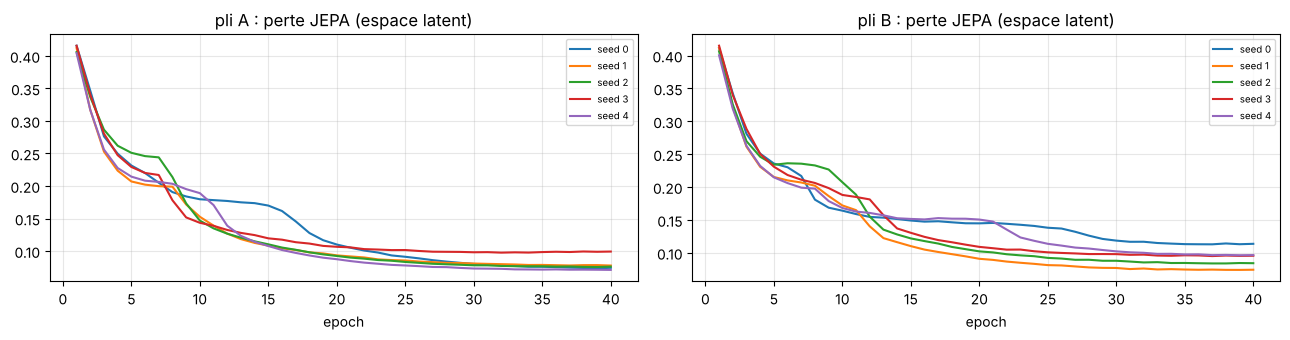

In [19]:
class Classifier(nn.Module):
    def __init__(self, encoder):
        super().__init__()
        self.enc = encoder
        self.head = nn.Sequential(nn.Linear(3 * D_MODEL, 64), nn.GELU(), nn.Linear(64, 1))
    def forward(self, x):
        return self.head(pool(self.enc(x))).squeeze(-1)

def finetune(encoder, Xn, tr, seed):
    torch.manual_seed(seed); gen = np.random.default_rng(seed)
    clf = Classifier(encoder)
    opt = torch.optim.AdamW([{"params": clf.enc.parameters(), "lr": 2e-4}, {"params": clf.head.parameters(), "lr": 1e-3}], weight_decay=0.05)
    ytr = torch.from_numpy(y_all[tr].astype(np.float32)); pos_w = (1 - ytr.mean()) / ytr.mean()
    for ep in range(FT_EPOCHS):
        clf.train(); perm = gen.permutation(len(tr))
        for i in range(0, len(tr), BATCH_SIZE):
            j = perm[i:i + BATCH_SIZE]
            loss = F.binary_cross_entropy_with_logits(clf(windows(Xn, tr[j])), ytr[j], pos_weight=pos_w)
            opt.zero_grad(); loss.backward(); opt.step()
    clf.eval()
    return clf

# Les scores JEPA sont mis en cache : relancer l'analyse ne refait pas l'heure de calcul (RECALCULER_JEPA = True pour tout refaire).
RECALCULER_JEPA = False
CACHE = RESULTS_DIR / "scores_jepa.pkl"
HIST = {}
t0 = time.time()
if CACHE.exists() and not RECALCULER_JEPA:
    cached = pd.read_pickle(CACHE)
    for k in FD:
        SCORES[k].update(cached["scores"][k])
    HIST = cached["hist"]
    print(f"Scores JEPA relus depuis {CACHE}. Journal du calcul d'origine :")
    print(cached.get("journal", ""))
for k, F_ in ({} if HIST else FD).items():
    Xn, tr, te = F_["Xn"], F_["tr"], F_["te"]
    pre_idx = ends_all[FOLDS[k]["train"][ends_all]]
    for s in SEEDS:
        model, HIST[(k, s)] = pretrain(Xn, pre_idx, s)
        torch.save(model.state_dict(), RESULTS_DIR / f"jepa_capteurs_pli{k}_seed{s}.pt")
        Z = batched(model.embed, Xn, ends_all); Zs = pd.DataFrame(Z, index=ends_all)
        Ztr, Zref = Zs.loc[tr].values, Zs.loc[F_["ref"]].values
        probe = logreg().fit(Ztr, y_all[tr])
        put(k, f"JEPA + sonde linéaire (seed {s})", ends_all, probe.predict_proba(Z)[:, 1])
        put(k, f"JEPA surprise, non supervisé (seed {s})", ends_all, batched(model.surprise, Xn, ends_all))
        sc = StandardScaler().fit(Zref)
        nn_ = NearestNeighbors(n_neighbors=KNN).fit(sc.transform(Zref))
        dist = nn_.kneighbors(sc.transform(Z))[0].mean(1)
        put(k, f"JEPA distance à la normale, non supervisé (seed {s})", ends_all, dist)
        gbz = HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=300, random_state=s)
        gbz.fit(np.hstack([F_["H"][np.searchsorted(ends_all, tr)], Ztr]), y_all[tr])
        put(k, f"Boosting variables manuelles + embeddings JEPA (seed {s})", ends_all, gbz.predict_proba(np.hstack([F_["H"], Z]))[:, 1])
        for init in ["JEPA", "aléatoire"]:
            if init == "JEPA":
                enc = copy.deepcopy(model.target); [p.requires_grad_(True) for p in enc.parameters()]
            else:
                torch.manual_seed(100 + s); enc = Encoder(Xn.shape[1])
            clf = finetune(enc, Xn, tr, s)
            nm = "initialisé par le JEPA" if init == "JEPA" else "initialisation aléatoire"
            put(k, f"Transformer supervisé, {nm} (seed {s})", ends_all, batched(lambda x: torch.sigmoid(clf(x)), Xn, ends_all))
        print(f"pli {k} seed {s} terminée ({time.time() - t0:.0f} s cumulées), perte finale {HIST[(k, s)][-1]:.4f}")
if not CACHE.exists() or RECALCULER_JEPA:
    pd.to_pickle({"scores": {k: {n: v for n, v in SCORES[k].items() if "seed" in n} for k in FD}, "hist": HIST}, CACHE)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
for (k, s), h in HIST.items():
    ax["AB".index(k)].plot(range(1, EPOCHS + 1), h, label=f"seed {s}")
for i, k in enumerate("AB"):
    ax[i].set_title(f"pli {k} : perte JEPA (espace latent)"); ax[i].set_xlabel("epoch"); ax[i].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 7. Résultats

### 7.1 ROC-AUC et PR-AUC sur le test (instant par instant)

Pour chaque famille de modèles JEPA, on donne la moyenne et l'écart-type sur 5 seeds, ainsi que l'**ensemble** (moyenne des scores des 5 seeds, après passage en rangs pour les scores non supervisés). La PR-AUC est à comparer au taux de positifs (score d'un modèle au hasard).

In [20]:
import re
def famille(n): return re.sub(r" \(seed \d+\)", "", n)
for k in FD:
    fams = {}
    for n in list(SCORES[k]):
        if "(seed" in n: fams.setdefault(famille(n), []).append(n)
    for f, ns in fams.items():
        r = np.mean([pd.Series(SCORES[k][n]).rank(pct=True).values for n in ns], axis=0)
        SCORES[k][f + " — ensemble 5 seeds"] = np.where(np.isnan(SCORES[k][ns[0]]), np.nan, r)

res = pd.concat([auc_table(k) for k in FD])
res["famille"] = res.modele.map(famille)
summ = res.groupby(["famille", "pli"]).roc_auc.agg(["mean", "std", "count"]).unstack("pli")
summ.columns = [f"{a} {b}" for a, b in summ.columns]
summ["ROC-AUC moyenne des 2 plis"] = (summ["mean A"] + summ["mean B"]) / 2
pr = res.groupby(["famille", "pli"]).pr_auc.mean().unstack("pli").add_prefix("PR-AUC ")
summ = summ.join(pr).sort_values("ROC-AUC moyenne des 2 plis", ascending=False)
print("Taux de positifs (PR-AUC du hasard) :", {k: round(y_all[FD[k]["te"]].mean(), 3) for k in FD})
display(summ[["mean A", "std A", "mean B", "std B", "ROC-AUC moyenne des 2 plis", "PR-AUC A", "PR-AUC B"]].round(3))
res.to_csv(RESULTS_DIR / "metriques_instant.csv", index=False)

Taux de positifs (PR-AUC du hasard) : {'A': np.float64(0.374), 'B': np.float64(0.4)}


,mean A,std A,mean B,std B,ROC-AUC moyenne des 2 plis,PR-AUC A,PR-AUC B
famille,,,,,,,
EWMA vibration (z-score),0.713,NaN,0.758,NaN,0.735,0.549,0.691
Résidus physiques (max),0.731,NaN,0.736,NaN,0.734,0.558,0.570
Seuil de température (24 h),0.750,NaN,0.658,NaN,0.704,0.704,0.567
Boosting variables manuelles + embeddings JEPA — ensemble 5 seeds,0.753,NaN,0.652,NaN,0.702,0.701,0.535
Boosting variables manuelles + embeddings JEPA,0.707,0.076,0.643,0.035,0.675,0.635,0.528
"Transformer supervisé, initialisé par le JEPA — ensemble 5 seeds",0.573,NaN,0.714,NaN,0.643,0.427,0.575
Gradient boosting (variables manuelles),0.658,NaN,0.626,NaN,0.642,0.557,0.458
JEPA + sonde linéaire — ensemble 5 seeds,0.602,NaN,0.677,NaN,0.640,0.476,0.561
"Transformer supervisé, initialisé par le JEPA",0.568,0.055,0.705,0.021,0.637,0.466,0.571


### 7.2 Intervalles de confiance et comparaisons appariées

Intervalle de confiance à 95 % de la ROC-AUC, par **bootstrap par jour** (on rééchantillonne des journées entières, car les heures d'une même journée sont corrélées), sur les deux plis réunis : chaque instant est noté par le modèle du pli qui ne l'a pas vu à l'entraînement. Les scores sont passés en rangs dans chaque pli pour être comparables.

Comme les pannes sont peu nombreuses et très corrélées dans le temps, les intervalles restent larges : **9 pannes par pli**.

In [21]:
CLES = ["Hasard (bruit lissé, référence)", "Seuil de température (24 h)", "EWMA vibration (z-score)", "Résidus physiques (max)",
        "Régression logistique (variables manuelles)", "Gradient boosting (variables manuelles)",
        "JEPA + sonde linéaire — ensemble 5 seeds", "JEPA distance à la normale, non supervisé — ensemble 5 seeds",
        "JEPA surprise, non supervisé — ensemble 5 seeds", "Boosting variables manuelles + embeddings JEPA — ensemble 5 seeds",
        "Transformer supervisé, initialisé par le JEPA — ensemble 5 seeds", "Transformer supervisé, initialisation aléatoire — ensemble 5 seeds"]
te_all = np.r_[FD["A"]["te"], FD["B"]["te"]]
yy = y_all[te_all]
def pooled(name):
    return np.r_[pd.Series(SCORES["A"][name][FD["A"]["te"]]).rank(pct=True).values,
                 pd.Series(SCORES["B"][name][FD["B"]["te"]]).rank(pct=True).values]
days = pd.DatetimeIndex(t_pred[te_all]).normalize(); uniq = days.unique(); groups = [np.where(days == d)[0] for d in uniq]
rng = np.random.default_rng(0)
BOOT = [np.concatenate([groups[j] for j in rng.integers(0, len(uniq), len(uniq))]) for _ in range(500)]
P = {n: pooled(n) for n in CLES}
ci = []
for n in CLES:
    v = [roc_auc_score(yy[b], P[n][b]) for b in BOOT]
    ci.append({"modele": n, "ROC-AUC (2 plis)": roc_auc_score(yy, P[n]), "IC95 bas": np.percentile(v, 2.5), "IC95 haut": np.percentile(v, 97.5)})
ci = pd.DataFrame(ci).set_index("modele"); display(ci.round(3))

def diff_ci(a, b):
    d = [roc_auc_score(yy[x], P[a][x]) - roc_auc_score(yy[x], P[b][x]) for x in BOOT]
    return roc_auc_score(yy, P[a]) - roc_auc_score(yy, P[b]), *np.percentile(d, [2.5, 97.5]), np.mean(np.array(d) <= 0)
comp = [("JEPA + sonde linéaire — ensemble 5 seeds", "Gradient boosting (variables manuelles)"),
        ("JEPA distance à la normale, non supervisé — ensemble 5 seeds", "Résidus physiques (max)"),
        ("Boosting variables manuelles + embeddings JEPA — ensemble 5 seeds", "Gradient boosting (variables manuelles)"),
        ("Transformer supervisé, initialisé par le JEPA — ensemble 5 seeds", "Transformer supervisé, initialisation aléatoire — ensemble 5 seeds")]
display(pd.DataFrame([dict(zip(["A", "B", "écart ROC-AUC", "IC95 bas", "IC95 haut", "part bootstrap ≤ 0"], (a, b) + diff_ci(a, b))) for a, b in comp]).round(3))

ft = res[res.famille.str.startswith("Transformer supervisé") & ~res.modele.str.contains("ensemble")].copy()
ft["seed"] = ft.modele.str.extract(r"seed (\d)").astype(int); ft["init"] = np.where(ft.famille.str.contains("JEPA"), "JEPA", "aléatoire")
pv = ft.pivot_table(index=["pli", "seed"], columns="init", values="roc_auc"); pv["écart JEPA - aléatoire"] = pv.JEPA - pv["aléatoire"]
print(f"Fine-tuning : JEPA meilleur que l'initialisation aléatoire sur {(pv['écart JEPA - aléatoire'] > 0).sum()}/{len(pv)} couples (pli, seed), "
      f"écart moyen {pv['écart JEPA - aléatoire'].mean():+.3f}")
display(pv.round(3))

,ROC-AUC (2 plis),IC95 bas,IC95 haut
modele,,,
"Hasard (bruit lissé, référence)",0.494,0.440,0.555
Seuil de température (24 h),0.701,0.641,0.761
EWMA vibration (z-score),0.737,0.680,0.787
Résidus physiques (max),0.734,0.674,0.787
Régression logistique (variables manuelles),0.620,0.555,0.688
Gradient boosting (variables manuelles),0.641,0.577,0.702
JEPA + sonde linéaire — ensemble 5 seeds,0.643,0.583,0.702
"JEPA distance à la normale, non supervisé — ensemble 5 seeds",0.604,0.535,0.669
"JEPA surprise, non supervisé — ensemble 5 seeds",0.606,0.536,0.656


,A,B,écart ROC-AUC,IC95 bas,IC95 haut,part bootstrap ≤ 0
0,JEPA + sonde linéaire — ensemble 5 seeds,Gradient boosting (variables manuelles),0.002,-0.055,0.057,0.494
1,"JEPA distance à la normale, non supervisé — en...",Résidus physiques (max),-0.130,-0.216,-0.048,0.998
2,Boosting variables manuelles + embeddings JEPA...,Gradient boosting (variables manuelles),0.057,0.011,0.097,0.006
3,"Transformer supervisé, initialisé par le JEPA ...","Transformer supervisé, initialisation aléatoir...",0.033,0.013,0.050,0.000


Fine-tuning : JEPA meilleur que l'initialisation aléatoire sur 9/10 couples (pli, seed), écart moyen +0.029


init       JEPA  aléatoire  écart JEPA - aléatoire
pli seed                                          
A   0     0.625      0.577                   0.048
    1     0.564      0.606                  -0.041
    2     0.599      0.581                   0.018
    3     0.479      0.466                   0.014
    4     0.573      0.547                   0.026
B   0     0.686      0.657                   0.028
    1     0.738      0.681                   0.057
    2     0.708      0.688                   0.020
    3     0.707      0.651                   0.056
    4     0.686      0.620                   0.066

### 7.3 Par type de défaut

ROC-AUC restreinte aux instants positifs d'un type (panne de ce type dans les 7 jours) contre tous les instants négatifs, sur les 2 plis réunis.

In [22]:
tp = type_suiv[te_all]
rows = []
for n in CLES:
    r = {"modele": n}
    for t in ["roulement", "courroie", "blocage", "electrique_brutal"]:
        m = (yy == 0) | (tp == t)
        r[t] = roc_auc_score(yy[m], P[n][m])
    rows.append(r)
par_type = pd.DataFrame(rows).set_index("modele")
par_type.to_csv(RESULTS_DIR / "roc_auc_par_type.csv")
display(par_type.round(3).style.background_gradient(cmap="RdYlGn", vmin=.4, vmax=1))

,roulement,courroie,blocage,electrique_brutal
modele,,,,
"Hasard (bruit lissé, référence)",0.377000,0.482000,0.448000,0.808000
Seuil de température (24 h),0.871000,0.765000,0.519000,0.530000
EWMA vibration (z-score),0.931000,0.768000,0.613000,0.492000
Résidus physiques (max),0.871000,0.735000,0.718000,0.492000
Régression logistique (variables manuelles),0.720000,0.580000,0.600000,0.528000
Gradient boosting (variables manuelles),0.718000,0.663000,0.636000,0.460000
JEPA + sonde linéaire — ensemble 5 seeds,0.874000,0.642000,0.505000,0.407000
"JEPA distance à la normale, non supervisé — ensemble 5 seeds",0.760000,0.570000,0.550000,0.446000
"JEPA surprise, non supervisé — ensemble 5 seeds",0.813000,0.561000,0.501000,0.443000


### 7.4 Au niveau des pannes : détection, avance, fausses alertes

C'est la mesure qui compte pour un technicien. Pour chaque modèle et chaque pli :
- **même budget de fausses alertes pour tous** : le seuil de chaque modèle est réglé pour que 5 % des heures **saines** du test dépassent le seuil. Les modèles sont donc comparés à taux de fausses alertes égal. Ce seuil n'est pas déployable tel quel (il utilise le test) ; un premier essai avec un seuil réglé sur le train donnait des modèles supervisés en alerte presque tout le temps, parce que leurs scores sur le train sont sur-ajustés ;
- une **alerte** se déclenche quand le score dépasse le seuil sur 2 tokens de suite (4 heures) ;
- une panne est **anticipée** si une alerte se déclenche **pendant que le défaut se développe**, entre le début de la dégradation (connu grâce à la vérité terrain) et la panne ; l'**avance** est le délai entre la première de ces alertes et la panne. Une alerte antérieure au début du défaut ne compte pas : avec une panne tous les 18 jours en moyenne, une fenêtre fixe de 14 jours attribuait à une panne les alertes d'un défaut précédent (un premier essai « anticipait » ainsi les 3 pannes électriques, imprévisibles par construction). Pour un défaut électrique, la fenêtre ne dure que 15 minutes ;
- les **fausses alertes** se mesurent en % d'heures actives en alerte pendant les périodes **saines** du test et pendant chaque **anomalie bénigne**. Une heure est saine si aucun défaut n'est en cours ni ne survient dans les 14 jours, et si elle ne tombe pas dans les **48 heures qui suivent une panne ou une maintenance**. Ces 48 h sont écartées parce que les scores lissés (EWMA) mettent du temps à redescendre après une réparation ; en usine, on réinitialiserait le détecteur après chaque intervention. Sans cette exclusion, plus de 40 % des heures « saines » étaient des heures post-réparation, et les seuils des détecteurs lissés montaient en conséquence ;
- il reste environ 670 heures saines sur les deux tests (une panne tous les 18 jours laisse peu de temps sain) : les taux de fausses alertes sont donc **bruités** ;
- on mesure aussi le % d'heures en alerte pendant les **dégradations préventives** : là, une alerte est *souhaitable*.

In [23]:
gt_h_fault = (gt.fault_type.fillna("").ne("")).resample(TOKEN).max().reindex(hours).fillna(False).values
f14 = np.zeros(len(hours), bool)
for f in faults.itertuples():
    f14 |= (t_pred > f.fin - pd.Timedelta(days=DETECT_WINDOW_D)) & (t_pred <= f.fin)
post_rep = np.zeros(len(hours), bool)                      # 48 h après une panne ou une maintenance
for f in faults.itertuples():
    post_rep |= (t_pred > f.fin) & (t_pred <= f.fin + pd.Timedelta(days=2))
sain_strict = actif & ~gt_h_fault & ~f14 & ~prev_h & ~post_rep & ~np.any(list(benin_h.values()), axis=0)
te_any = FOLDS["A"]["test"] | FOLDS["B"]["test"]
print(f"Heures saines de référence sur les tests : {TOK_H * (sain_strict & te_any).sum()} h "
      f"({TOK_H * (actif & ~gt_h_fault & ~f14 & ~prev_h & post_rep & te_any).sum()} h post-réparation écartées)")

def alerts(k, name):
    # Alertes du modèle sur le pli k, avec un seuil fixé à ALERT_FPR des heures saines du test (budget de fausses alertes commun).
    s = SCORES[k][name]
    ok = sain_strict & FOLDS[k]["test"] & ~np.isnan(s)
    thr = np.nanquantile(s[ok], 1 - ALERT_FPR)
    above = np.nan_to_num(s, nan=-np.inf) > thr
    run_ = pd.Series(above).rolling(PERSIST).sum().values >= PERSIST
    return run_ & actif, thr

def event_eval(name):
    det, fa = [], {}
    for k in FD:
        al, thr = alerts(k, name)
        te_mask = np.zeros(len(hours), bool); te_mask[FD[k]["te"]] = True
        te_span = FOLDS[k]["test"]
        for f in faults.itertuples():
            if not te_span[np.searchsorted(t_pred, f.fin) - 1]: continue
            w = (t_pred > f.onset) & (t_pred <= f.fin) & te_span          # pendant que le défaut se développe
            first = t_pred[w & al].min() if (w & al).any() else pd.NaT
            det.append({"pli": k, "defaut": f.fault_id, "type": f.type, "panne": f.panne, "anticipe": pd.notna(first),
                        "avance_j": (f.fin - first).total_seconds() / 86400 if pd.notna(first) else np.nan})
        for nm, m in {"sain": sain_strict, "préventif": prev_h & actif, **{f"bénin : {b}": v & actif for b, v in benin_h.items()}}.items():
            mm = m & te_span
            fa.setdefault(nm, [0, 0]); fa[nm][0] += (al & mm).sum(); fa[nm][1] += mm.sum()
    det = pd.DataFrame(det)
    out = {"pannes anticipées": f"{det[det.panne].anticipe.sum()}/{det.panne.sum()}",
           "avance médiane (j)": det[det.panne].avance_j.median()}
    for t in ["roulement", "courroie", "blocage", "electrique_brutal"]:
        d = det[det.panne & (det.type == t)]; out[t] = f"{d.anticipe.sum()}/{len(d)}"
    for nm, (a, b) in fa.items():
        out[f"% h en alerte, {nm}"] = 100 * a / b if b else np.nan
    return out, det

ev_rows, DET = [], {}
for n in CLES:
    o, d = event_eval(n); ev_rows.append({"modele": n, **o}); DET[n] = d
ev = pd.DataFrame(ev_rows).set_index("modele")
ev.to_csv(RESULTS_DIR / "metriques_pannes.csv")
display(ev.round(1))
print("Heures actives par période de test :", {nm: int((m & actif & (FOLDS['A']['test'] | FOLDS['B']['test'])).sum())
                                               for nm, m in {"sain": sain_strict, "préventif": prev_h, **benin_h}.items()})

Heures saines de référence sur les tests : 670 h (516 h post-réparation écartées)


,pannes anticipées,avance médiane (j),roulement,courroie,blocage,electrique_brutal,"% h en alerte, sain","% h en alerte, préventif","% h en alerte, bénin : canicule","% h en alerte, bénin : dérive capteur T","% h en alerte, bénin : capteur T figé","% h en alerte, bénin : perte de données"
modele,,,,,,,,,,,,
"Hasard (bruit lissé, référence)",6/18,11.8,3/6,3/5,0/4,0/3,3.0,3.1,0.0,3.8,0.0,16.7
Seuil de température (24 h),15/18,4.6,6/6,5/5,4/4,0/3,3.9,22.4,100.0,21.7,0.0,58.3
EWMA vibration (z-score),10/18,5.9,6/6,3/5,1/4,0/3,3.0,29.8,45.0,30.2,0.0,75.0
Résidus physiques (max),5/18,2.4,4/6,1/5,0/4,0/3,3.0,3.3,100.0,30.2,0.0,58.3
Régression logistique (variables manuelles),4/18,3.1,2/6,1/5,1/4,0/3,0.9,9.8,0.0,0.0,0.0,0.0
Gradient boosting (variables manuelles),12/18,4.0,6/6,4/5,2/4,0/3,4.2,34.1,63.3,4.7,0.0,0.0
JEPA + sonde linéaire — ensemble 5 seeds,12/18,2.7,6/6,4/5,2/4,0/3,3.0,30.8,100.0,0.0,0.0,0.0
"JEPA distance à la normale, non supervisé — ensemble 5 seeds",6/18,8.7,2/6,2/5,2/4,0/3,3.9,0.0,0.0,0.0,0.0,0.0
"JEPA surprise, non supervisé — ensemble 5 seeds",11/18,3.1,6/6,3/5,2/4,0/3,4.5,14.1,46.7,1.9,0.0,33.3


Heures actives par période de test : {'sain': 335, 'préventif': 510, 'canicule': 60, 'dérive capteur T': 106, 'capteur T figé': 6, 'perte de données': 12}


### 7.5 Avance par panne

Avance (en jours) de la première alerte avant chaque panne, pour quelques modèles. Une case vide signifie panne manquée.

In [24]:
sel = ["EWMA vibration (z-score)", "Résidus physiques (max)", "Gradient boosting (variables manuelles)",
       "JEPA + sonde linéaire — ensemble 5 seeds", "JEPA distance à la normale, non supervisé — ensemble 5 seeds",
       "Transformer supervisé, initialisé par le JEPA — ensemble 5 seeds"]
av = pd.DataFrame({n: DET[n].set_index("defaut").avance_j for n in sel})
av.insert(0, "type", DET[sel[0]].set_index("defaut").type); av.insert(1, "pli", DET[sel[0]].set_index("defaut").pli)
av.insert(2, "panne", DET[sel[0]].set_index("defaut").panne)
display(av.round(1))

,type,pli,panne,EWMA vibration (z-score),Résidus physiques (max),Gradient boosting (variables manuelles),JEPA + sonde linéaire — ensemble 5 seeds,"JEPA distance à la normale, non supervisé — ensemble 5 seeds","Transformer supervisé, initialisé par le JEPA — ensemble 5 seeds"
defaut,,,,,,,,,
F12,roulement,A,True,7.0,7.0,13.0,1.1,NaN,1.2
F13,courroie,A,True,NaN,NaN,0.1,NaN,NaN,NaN
F14,roulement,A,True,2.0,2.0,1.3,1.1,NaN,1.9
F15,courroie,A,True,NaN,NaN,5.1,0.0,NaN,11.7
F16,electrique_brutal,A,True,NaN,NaN,NaN,NaN,NaN,NaN
F17,roulement,A,True,6.1,6.1,5.8,18.1,NaN,24.8
F18,roulement,A,True,2.4,2.4,2.0,15.8,15.8,15.8
F19,roulement,A,False,1.3,1.3,21.1,17.4,NaN,18.9
F20,blocage,A,True,NaN,NaN,1.6,NaN,NaN,NaN


## 8. Visualisation de la période de test

Scores de risque sur l'année, chaque instant étant noté par le modèle du pli qui ne l'a pas vu. Les pannes sont en traits rouges, les fenêtres de dégradation en rouge clair, les anomalies bénignes en orange, et le seuil d'alerte en pointillés.

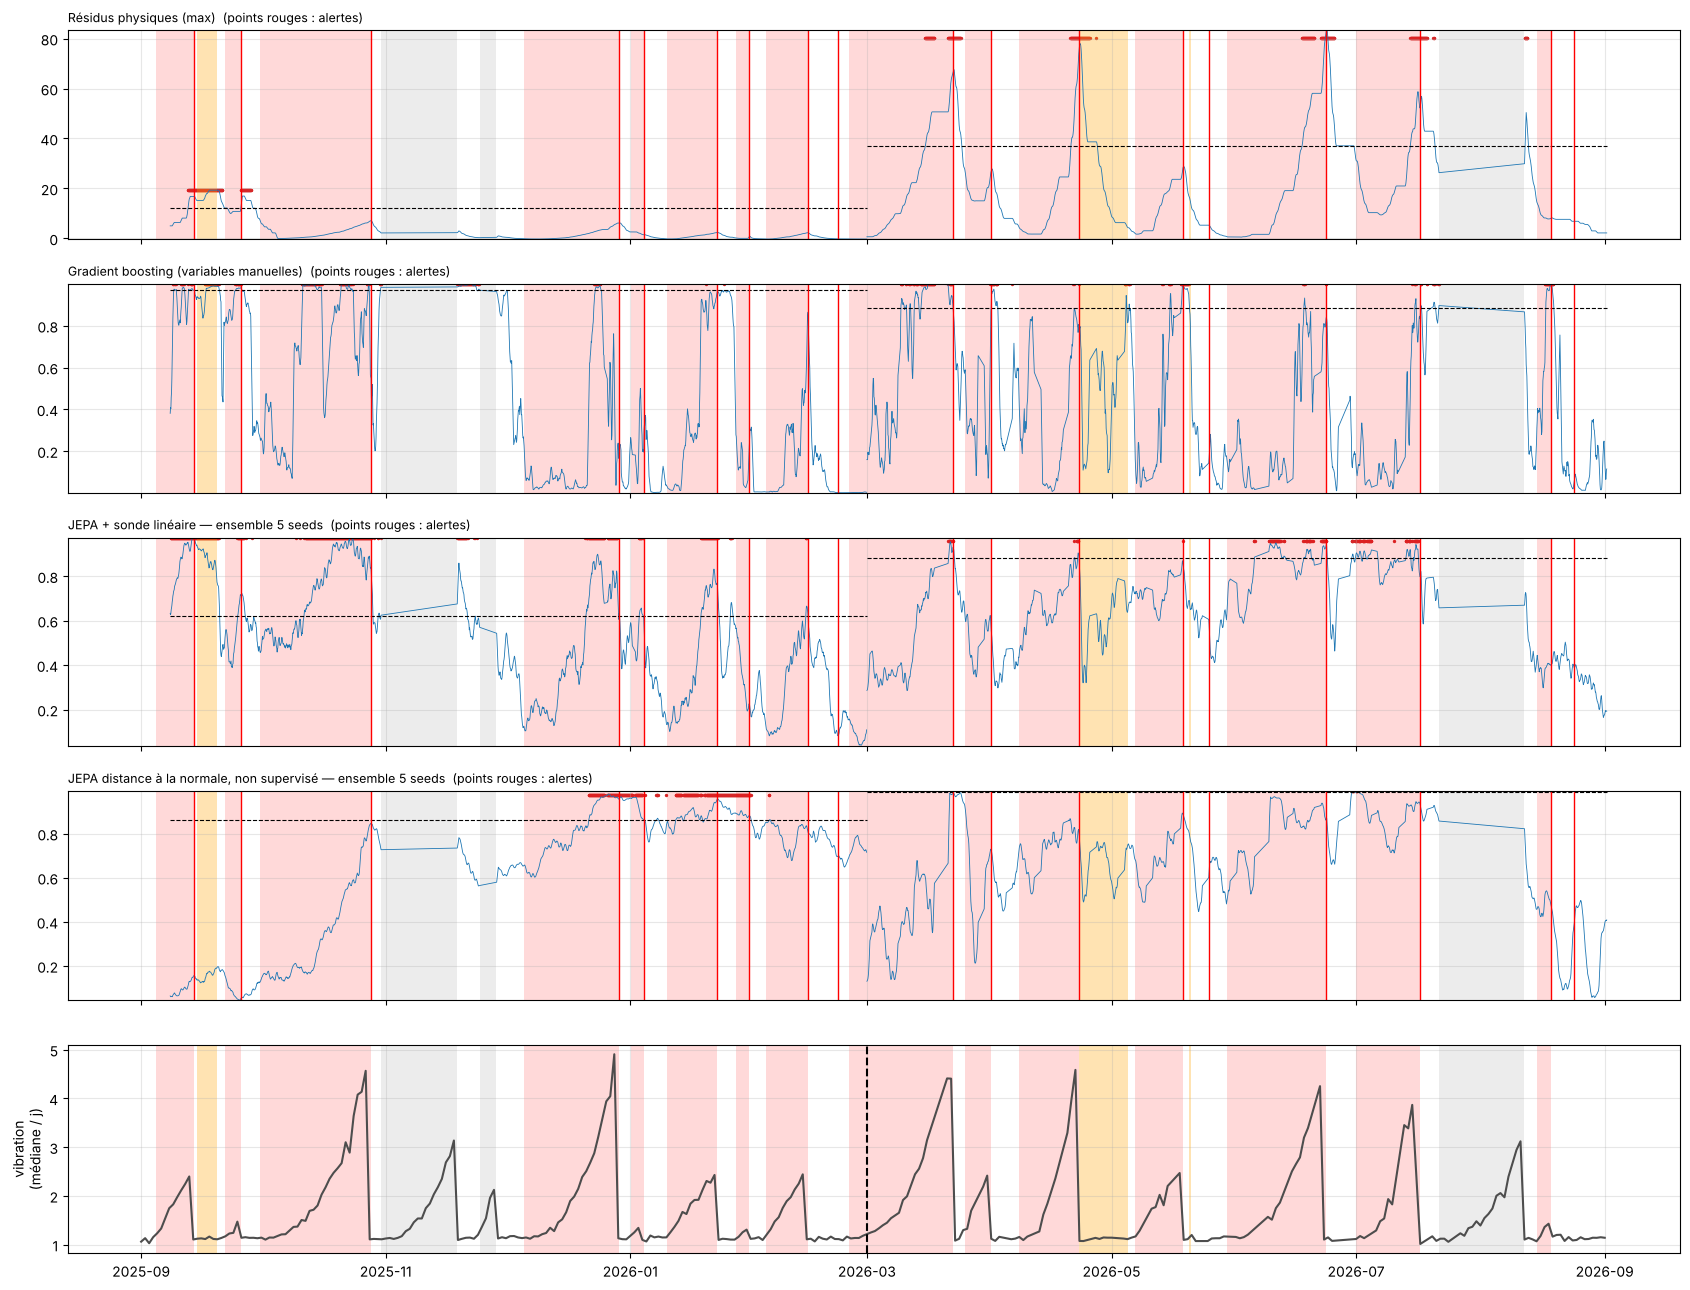

In [25]:
show = ["Résidus physiques (max)", "Gradient boosting (variables manuelles)", "JEPA + sonde linéaire — ensemble 5 seeds",
        "JEPA distance à la normale, non supervisé — ensemble 5 seeds"]
fig, ax = plt.subplots(len(show) + 1, 1, figsize=(17, 2.6 * (len(show) + 1)), sharex=True)
for a, n in zip(ax, show):
    for k in FD:
        te = FD[k]["te"]; s = SCORES[k][n]
        al, ref_q = alerts(k, n)
        a.plot(t_pred[te], pd.Series(s[te]).rolling(nt(12), min_periods=1).mean(), lw=.6, color="C0")
        a.hlines(ref_q, t_pred[te].min(), t_pred[te].max(), color="k", ls="--", lw=.8)
        m = al.copy(); m[:] = False; m[te] = al[te]
        a.scatter(t_pred[m], np.full(m.sum(), np.nanquantile(s[te], .995)), s=2, color="C3")
    ombrer(a); [a.axvline(f.fin, color="red", lw=1) for f in pannes.itertuples()]
    a.set_title(n + "  (points rouges : alertes)", fontsize=9, loc="left")
    a.set_ylim(np.nanquantile(np.r_[SCORES["A"][n][FD["A"]["te"]], SCORES["B"][n][FD["B"]["te"]]], [.001, .999]))
ax[-1].plot(day.index, day.vibration_mm_s, color="0.3"); ax[-1].set_ylabel("vibration\n(médiane / j)"); ombrer(ax[-1])
ax[-1].axvline(SPLIT, color="k", ls="--")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "risque_annee.png", dpi=110); plt.show()

### Zoom sur trois pannes

Une panne par type prévisible (roulement, courroie, blocage) : capteurs normalisés par la référence du produit en haut, sévérité réelle du défaut au milieu, scores en bas. On voit à quel moment chaque modèle franchit son seuil.

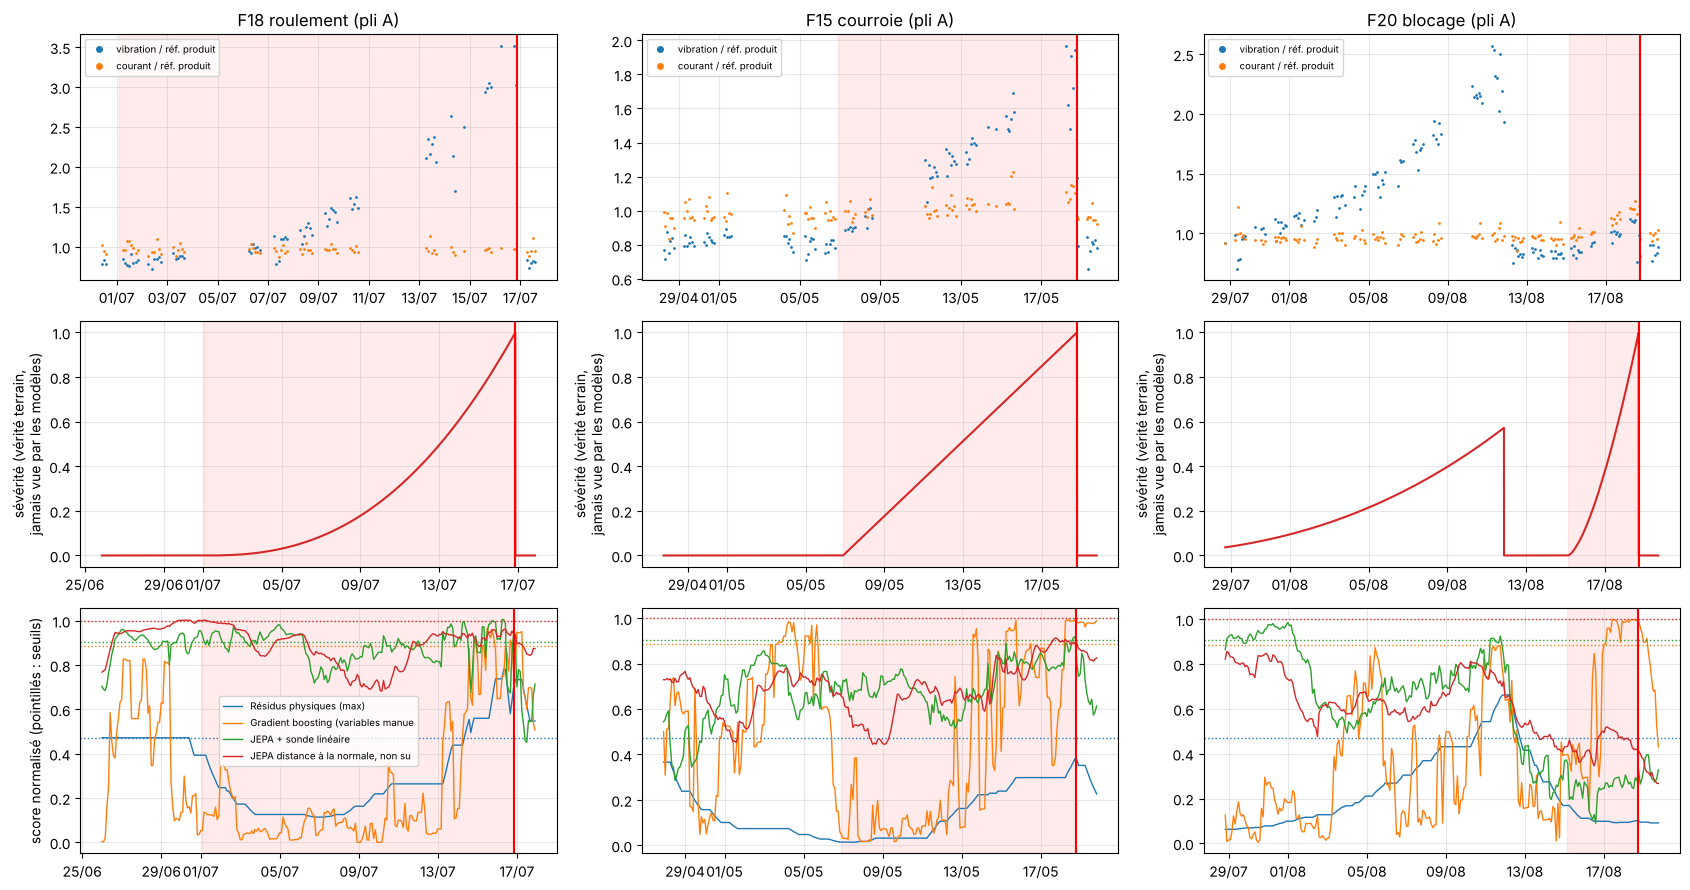

In [26]:
zoom = [pannes[pannes.type == t].iloc[-1] for t in ["roulement", "courroie", "blocage"]]
fig, ax = plt.subplots(3, 3, figsize=(17, 9))
for j, f in enumerate(zoom):
    d0, d1 = f.fin - pd.Timedelta(days=21), f.fin + pd.Timedelta(days=1)
    k = "A" if f.fin >= SPLIT else "B"
    T = FD[k]["T"]; m = (hours >= d0) & (hours < d1)
    on = (T.marche.values > .5) & (T.nan_vib.values == 0) & (T.nan_cour.values == 0)
    ax[0, j].plot(hours[m & on], (T.vib_moy / T.vib_ref)[m & on], ".", ms=2, label="vibration / réf. produit")
    ax[0, j].plot(hours[m & on], (T.cour_moy / T.cour_ref)[m & on], ".", ms=2, label="courant / réf. produit")
    ax[0, j].set_title(f"{f.fault_id} {f.type} (pli {k})"); ax[0, j].legend(fontsize=7, markerscale=4)
    sv = gt.severity.loc[d0:d1]
    ax[1, j].plot(sv.index, sv.values, color="C3"); ax[1, j].set_ylim(-0.05, 1.05)
    ax[1, j].set_ylabel("sévérité (vérité terrain,\njamais vue par les modèles)")
    for i, n in enumerate(show):
        s = SCORES[k][n]; _, thr = alerts(k, n)
        lo, hi = np.nanquantile(s[FD[k]["te"]], [.01, .99])
        ax[2, j].plot(t_pred[m], np.clip((s[m] - lo) / (hi - lo), 0, 1.2), lw=1, label=n.split(" —")[0][:34])
        ax[2, j].axhline((thr - lo) / (hi - lo), color=f"C{i}", ls=":", lw=1)
    for a in ax[:, j]:
        a.axvspan(f.onset, f.fin, color="red", alpha=.08); a.axvline(f.fin, color="red")
        a.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
ax[2, 0].legend(fontsize=7); ax[2, 0].set_ylabel("score normalisé (pointillés : seuils)")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "zoom_pannes.png", dpi=110); plt.show()

## 9. Hypothèses pré-enregistrées et conclusions

*Exécution du 13/10/2026 : 2 plis × 5 seeds × 40 epochs, environ 1 h de calcul sur CPU. **Rappel : données synthétiques.***

### Résultats principaux

| Modèle | ROC-AUC (2 plis, IC 95 %) | Pannes anticipées (budget 5 % de fausses alertes) | Avance médiane | Alerte pendant la canicule |
|---|---|---|---|---|
| Hasard (bruit lissé) | 0,49 [0,44 ; 0,56] | 6/18 | — | 0 % |
| **EWMA vibration** | **0,74** [0,68 ; 0,79] | 10/18 (roulements 6/6) | 5,9 j | 45 % |
| **Résidus physiques** | **0,73** [0,67 ; 0,79] | 5/18 | 2,4 j | 100 % |
| Seuil de température | 0,70 [0,64 ; 0,76] | **15/18** | 4,6 j | 100 % |
| Gradient boosting (variables manuelles) | 0,64 [0,58 ; 0,70] | 12/18 | 4,0 j | 63 % |
| JEPA + sonde linéaire | 0,64 [0,58 ; 0,70] | 12/18 | 2,7 j | 100 % |
| JEPA distance à la normale (non supervisé) | 0,60 [0,54 ; 0,67] | 6/18 | 8,7 j | 0 % |
| JEPA surprise (non supervisé) | 0,61 [0,54 ; 0,66] | 11/18 | 3,1 j | 47 % |
| Boosting + embeddings JEPA | 0,70 [0,64 ; 0,75] | 10/18 | 5,5 j | 100 % |
| Transformer supervisé, init. JEPA | 0,65 [0,59 ; 0,71] | 10/18 | 6,3 j | 100 % |
| Transformer supervisé, init. aléatoire | 0,62 [0,56 ; 0,68] | 10/18 | 7,0 j | 100 % |

1. **Le pré-entraînement JEPA aide, pour la première fois dans ce projet.** À architecture égale, le Transformer initialisé par le JEPA bat l'initialisation aléatoire de +0,033 de ROC-AUC (IC 95 % [+0,013 ; +0,050]), sur 9 couples (pli, seed) sur 10. Ajouter les embeddings JEPA au gradient boosting le fait passer de 0,64 à 0,70 (+0,057, IC [+0,011 ; +0,097]). Sur les logs d'arrêts de la mouleuse, le JEPA n'apportait rien : ce qui change ici, ce sont des **capteurs continus avec des dégradations lentes**, le cas pour lequel un modèle prédictif auto-supervisé a quelque chose à apprendre.
2. **Mais aucun modèle JEPA ne bat les détecteurs simples.** Une EWMA sur la vibration et des résidus physiques (régression capteur ~ contexte) obtiennent 0,73 à 0,74 sans aucune étiquette, contre 0,60 pour le meilleur score JEPA non supervisé (écart avec les résidus : -0,13, IC [-0,22 ; -0,05]). La sonde linéaire JEPA fait jeu égal avec le gradient boosting (+0,002, IC [-0,06 ; +0,06]).
3. **Les plis A et B donnent des résultats très différents** : par exemple, le Transformer initialisé par le JEPA obtient 0,57 sur le pli A et 0,71 sur le pli B. Avec 9 pannes par pli, l'ordre des modèles n'est stable que pour les grands écarts.
4. **Les modèles supervisés ont appris « chaud = panne ».** Le gradient boosting, la sonde JEPA et les Transformers sont en alerte 63 à 100 % du temps pendant la canicule bénigne, parce que presque toutes les pannes s'accompagnent d'un échauffement. Les scores JEPA non supervisés ne se trompent pas pendant la canicule (distance à la normale : 0 %), mais ils détectent peu.

### Hypothèses pré-enregistrées (README), sans réécriture

- **H1 (l'EWMA de vibration détecte les roulements) : confirmée.** Les 6 roulements sont anticipés, avec la meilleure ROC-AUC sur ce type (0,93). Le JEPA ne bat pas cette baseline ; comme le prévoyait le README, ce n'est pas un échec du JEPA, c'est le cas favorable aux statistiques.
- **H2 (un seuil de température déclenche de fausses alertes bénignes) : confirmée.** Le seuil est en alerte 100 % du temps pendant la canicule, 22 % pendant la dérive du capteur et 58 % pendant les pertes de données, contre 3,9 % en période saine. C'est pourtant le modèle qui anticipe le plus de pannes (15/18) : il est sensible, mais pas spécifique.
- **H3 (les pannes électriques brutales ne sont pas anticipables) : confirmée.** Aucun modèle n'en anticipe une (0/3 partout). Une première version de la mesure, avec une fenêtre fixe de 14 jours, en « anticipait » à tort, en comptant les alertes du défaut précédent ; c'est corrigé.
- **H4 (si le JEPA apporte un avantage, ce sera sur les blocages et la réduction des fausses alertes bénignes) : non confirmée.** Sur les blocages, la meilleure ROC-AUC est celle des résidus physiques (0,72), contre 0,51 pour la sonde JEPA et 0,55 pour sa distance à la normale. Sur les fausses alertes bénignes, le résultat est partagé : la sonde JEPA ne se déclenche ni pendant la dérive du capteur ni pendant les pertes de données (0 %), mais elle se déclenche pendant toute la canicule. Les scores JEPA non supervisés ne se déclenchent pas sur les événements bénins, mais ils manquent aussi la plupart des pannes.

### Limites

- **Données synthétiques et circulaires.** Les défauts et leurs signatures ont été écrits à la main : ces chiffres valident le pipeline, pas l'intérêt industriel du JEPA (voir le README).
- **Peu de pannes et peu d'heures saines.** Il y a 18 pannes, et environ 670 heures saines de référence sur les deux tests. Les écarts de moins de 0,05 de ROC-AUC et les taux de fausses alertes sont donc fragiles.
- **Seuils réglés sur le test.** Pour comparer les modèles à budget égal de fausses alertes, chaque seuil est réglé sur les heures saines du test. Un déploiement demanderait de les régler sur des données antérieures, et le premier essai a montré que c'est difficile pour les modèles supervisés.
- **Cible à 7 jours.** Un roulement met jusqu'à 28 jours à se dégrader, mais il reste invisible pendant les premiers jours. Une partie des instants positifs est donc imprévisible par construction, ce qui plafonne la ROC-AUC instant par instant.

### Pistes

1. **Résidus JEPA.** Entraîner le JEPA uniquement sur des périodes saines connues, et utiliser comme score l'erreur de prédiction des capteurs **à charge et produit donnés**. C'est l'idée de H4, que le score de surprise actuel ne teste qu'indirectement.
2. **Tokens normalisés par le contexte** : fournir au JEPA vibration / référence produit et température - ambiante, comme pour les résidus physiques, et mesurer ce que le pré-entraînement apporte en plus.
3. **Réinitialiser les détecteurs après chaque intervention**, puisque les dates de maintenance sont connues.
4. Le vrai test reste **des capteurs réels** sur la mouleuse, en particulier sur la zone pré-égouttage, la seule où les logs Teeptrak montraient un signal.
